# Bioreactor dataset: visual overview

This notebook gives a visual tour of the two files in `data/`:

| File | What it is |
|---|---|
| `bioreaction_remaining.csv` | Event log of **61 fed-batch bioreactor runs** (~13 days each): daily samples, feed additions and volume |
| `bioreaction_template.csv` | Submission template: **12 batches × 13 time points** where `vcd`, `tcd`, `substrate` and `byproduct` must be predicted (all zeros now) |

**Columns**

- `batch_id`, `elapsed_time` (days since inoculation)
- **Measured state:** `vcd` (viable cell density), `tcd` (total cell density), `substrate`, `byproduct`
- **Inputs:** `feed_substrate`, `feed_b`, `feed_c`, `feed_d` (amount added at one feed event), `volume` (reactor volume)
- `to_predict`: `True` on the rows whose measurements are hidden (the test set)

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

DATA = Path("../data")
raw = pd.read_csv(DATA / "bioreaction_remaining.csv")
template = pd.read_csv(DATA / "bioreaction_template.csv")

# Consistent styling: fixed colors per role, recessive grid
TRAIN, TEST, ACCENT = "#2a78d6", "#eb6834", "#1baf7a"
FEED_COLORS = {"feed_substrate": "#2a78d6", "feed_b": "#eb6834", "feed_c": "#1baf7a", "feed_d": "#6250d6"}
sns.set_theme(style="whitegrid", rc={
    "grid.color": "#e6e5e1", "axes.edgecolor": "#c3c2b7", "axes.titleweight": "bold",
    "axes.titlesize": 11, "axes.labelsize": 10, "figure.dpi": 110, "lines.linewidth": 2,
})

STATE = ["vcd", "tcd", "substrate", "byproduct"]
FEEDS = ["feed_substrate", "feed_b", "feed_c", "feed_d"]
LABELS = {"vcd": "Viable cell density", "tcd": "Total cell density", "substrate": "Substrate",
          "byproduct": "Byproduct", "volume": "Volume", "viability": "Viability (vcd / tcd)"}

test_batches = sorted(raw.loc[raw.to_predict, "batch_id"].unique(), key=lambda b: int(b[5:]))
raw["split"] = np.where(raw.batch_id.isin(test_batches), "test", "train")
print(f"remaining: {raw.shape[0]:,} rows × {raw.shape[1]-1} cols | template: {template.shape}")
print(f"{raw.batch_id.nunique()} batches: {raw.loc[raw.split=='train','batch_id'].nunique()} train, {len(test_batches)} test")
print("Test batches:", ", ".join(test_batches))
raw.head(8)

remaining: 2,858 rows × 12 cols | template: (156, 6)
61 batches: 49 train, 12 test
Test batches: Batch5, Batch6, Batch12, Batch24, Batch32, Batch35, Batch40, Batch48, Batch54, Batch56, Batch57, Batch60


,batch_id,elapsed_time,vcd,tcd,substrate,byproduct,feed_substrate,feed_b,feed_c,feed_d,volume,to_predict,split
0,Batch1,0.000000,0.979690,0.985251,4.507188,0.241840,NaN,NaN,NaN,NaN,10.500750,False,train
1,Batch1,0.996528,1.909271,1.929805,3.830345,0.940785,NaN,NaN,NaN,NaN,10.494285,False,train
2,Batch1,1.014977,NaN,NaN,NaN,NaN,NaN,0.062214,NaN,NaN,NaN,False,train
3,Batch1,1.984722,4.574543,4.611517,2.827742,1.860896,NaN,NaN,NaN,NaN,10.537027,False,train
4,Batch1,2.044421,NaN,NaN,NaN,NaN,NaN,0.136099,NaN,NaN,NaN,False,train
5,Batch1,2.722998,NaN,NaN,NaN,NaN,NaN,NaN,0.000854,NaN,NaN,False,train
6,Batch1,2.967361,7.489739,7.545903,2.362482,1.941632,NaN,NaN,NaN,NaN,10.695897,False,train
7,Batch1,2.981134,NaN,NaN,NaN,NaN,NaN,0.271894,NaN,NaN,NaN,False,train


## 1. What is a row?

The file is a **long event log**, not a regular table. Every row is exactly one kind of event,
so most cells are empty by design:

- **Sample**: the 4 state measurements + volume (roughly once per day)
- **Feed event**: exactly one of the four feeds is non-empty
- **To predict**: a sample in a test batch whose measurements are hidden (only volume is given)

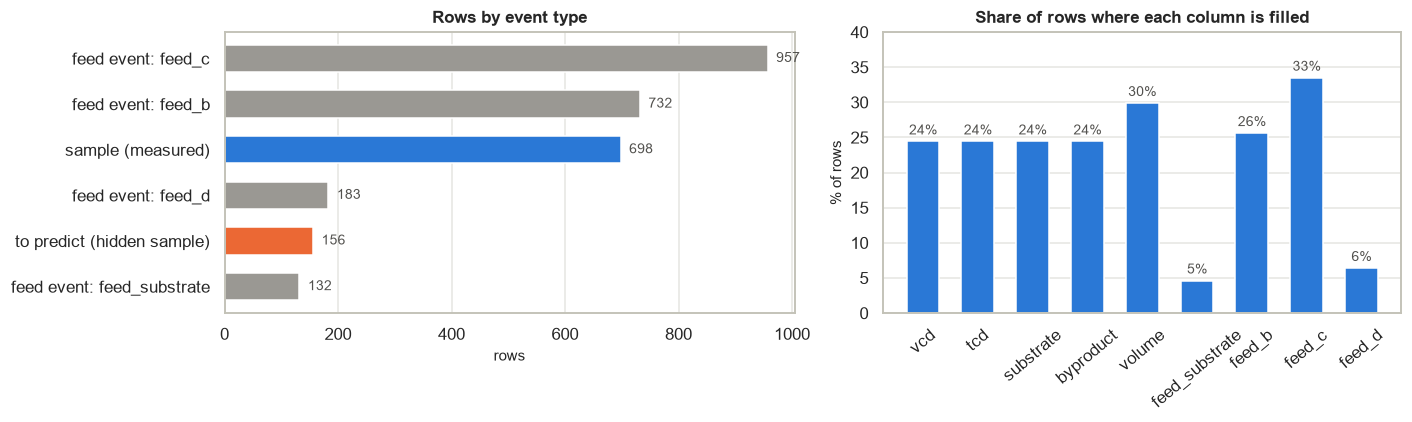

In [2]:
def row_type(r):
    if r.to_predict:
        return "to predict (hidden sample)"
    if pd.notna(r.vcd):
        return "sample (measured)"
    for f in FEEDS:
        if pd.notna(r[f]):
            return f"feed event: {f}"
    return "other"

raw["row_type"] = raw.apply(row_type, axis=1)
counts = raw.row_type.value_counts()

fig, axes = plt.subplots(1, 2, figsize=(13, 4), gridspec_kw={"width_ratios": [1.1, 1]})
ax = axes[0]
colors = [TEST if "predict" in t else TRAIN if "sample" in t else "#9a9893" for t in counts.index]
ax.barh(counts.index[::-1], counts.values[::-1], color=colors[::-1], height=0.6)
for y, v in enumerate(counts.values[::-1]):
    ax.text(v + 15, y, f"{v:,}", va="center", fontsize=9, color="#52514e")
ax.set_title("Rows by event type")
ax.set_xlabel("rows"); ax.grid(axis="y", visible=False)

ax = axes[1]
order = ["vcd", "tcd", "substrate", "byproduct", "volume"] + FEEDS
filled = raw[order].notna().mean().mul(100)
ax.bar(order, filled.values, color=TRAIN, width=0.6)
for x, v in enumerate(filled.values):
    ax.text(x, v + 1, f"{v:.0f}%", ha="center", fontsize=9, color="#52514e")
ax.set_title("Share of rows where each column is filled")
ax.set_ylabel("% of rows"); ax.set_ylim(0, 40); ax.tick_params(axis="x", rotation=40)
ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()

## 2. Train / test split

49 batches are fully observed. In the 12 test batches only the **day-0 sample** is measured;
every later daily sample is hidden (`to_predict`). Feeds and volume stay visible for all batches,
so the task is to predict the state trajectory from initial conditions + inputs.

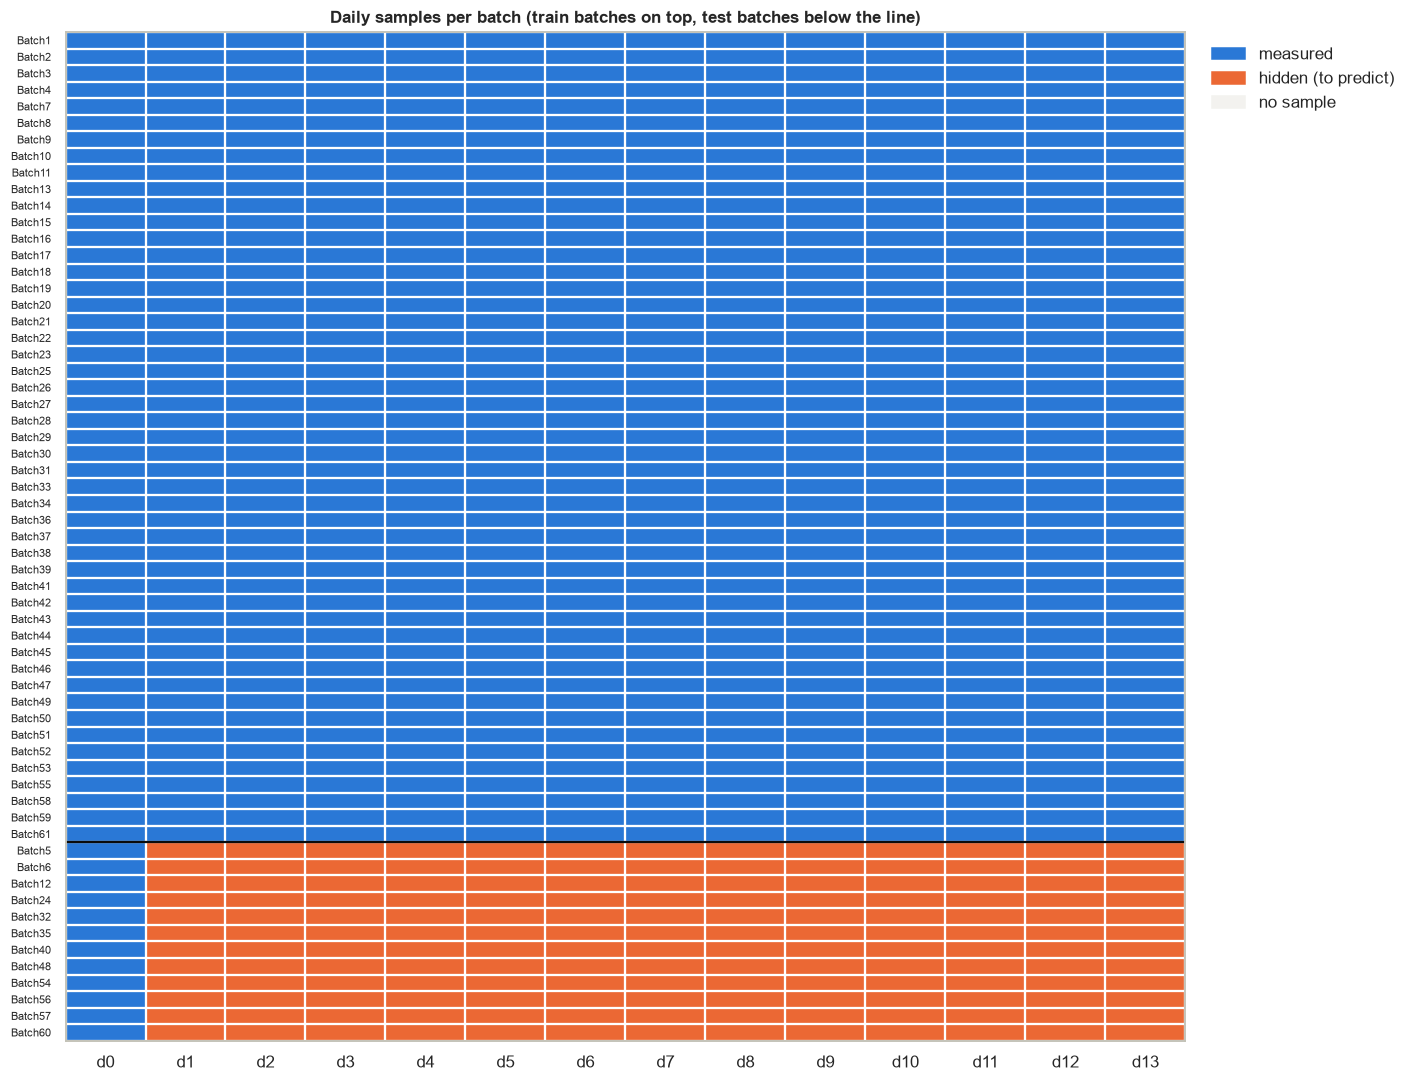

Template rows match the to_predict rows exactly: True


In [3]:
samples = raw[(raw.row_type == "sample (measured)") | raw.to_predict].copy()
grid = samples.assign(day=samples.elapsed_time.round().astype(int),
                      status=np.where(samples.to_predict, 2, 1))
pivot = grid.pivot_table(index="batch_id", columns="day", values="status", aggfunc="max").fillna(0)
pivot = pivot.loc[sorted(pivot.index, key=lambda b: (b in test_batches, int(b[5:])))]

fig, ax = plt.subplots(figsize=(13, 10))
cmap = plt.matplotlib.colors.ListedColormap(["#f3f2ef", TRAIN, TEST])
ax.imshow(pivot.values, aspect="auto", cmap=cmap, vmin=0, vmax=2, interpolation="none")
ax.set_xticks(range(pivot.shape[1]), [f"d{d}" for d in pivot.columns])
ax.set_yticks(range(len(pivot)), pivot.index, fontsize=7)
ax.set_xticks(np.arange(-.5, pivot.shape[1]), minor=True); ax.set_yticks(np.arange(-.5, len(pivot)), minor=True)
ax.grid(which="minor", color="white", linewidth=1.5); ax.grid(which="major", visible=False)
ax.tick_params(which="minor", length=0)
ax.axhline(len(pivot) - len(test_batches) - 0.5, color="#0b0b0b", linewidth=1.5)
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in [TRAIN, TEST, "#f3f2ef"]]
ax.legend(handles, ["measured", "hidden (to predict)", "no sample"], loc="upper left",
          bbox_to_anchor=(1.01, 1), frameon=False)
ax.set_title("Daily samples per batch (train batches on top, test batches below the line)")
plt.tight_layout(); plt.show()

check = (template[["batch_id", "elapsed_time"]].sort_values(["batch_id", "elapsed_time"]).round(6).values ==
         raw.loc[raw.to_predict, ["batch_id", "elapsed_time"]].sort_values(["batch_id", "elapsed_time"]).round(6).values).all()
print("Template rows match the to_predict rows exactly:", check)

## 3. Anatomy of one run

A single training batch laid out over time: daily samples, and the four feeds with their
distinct schedules.

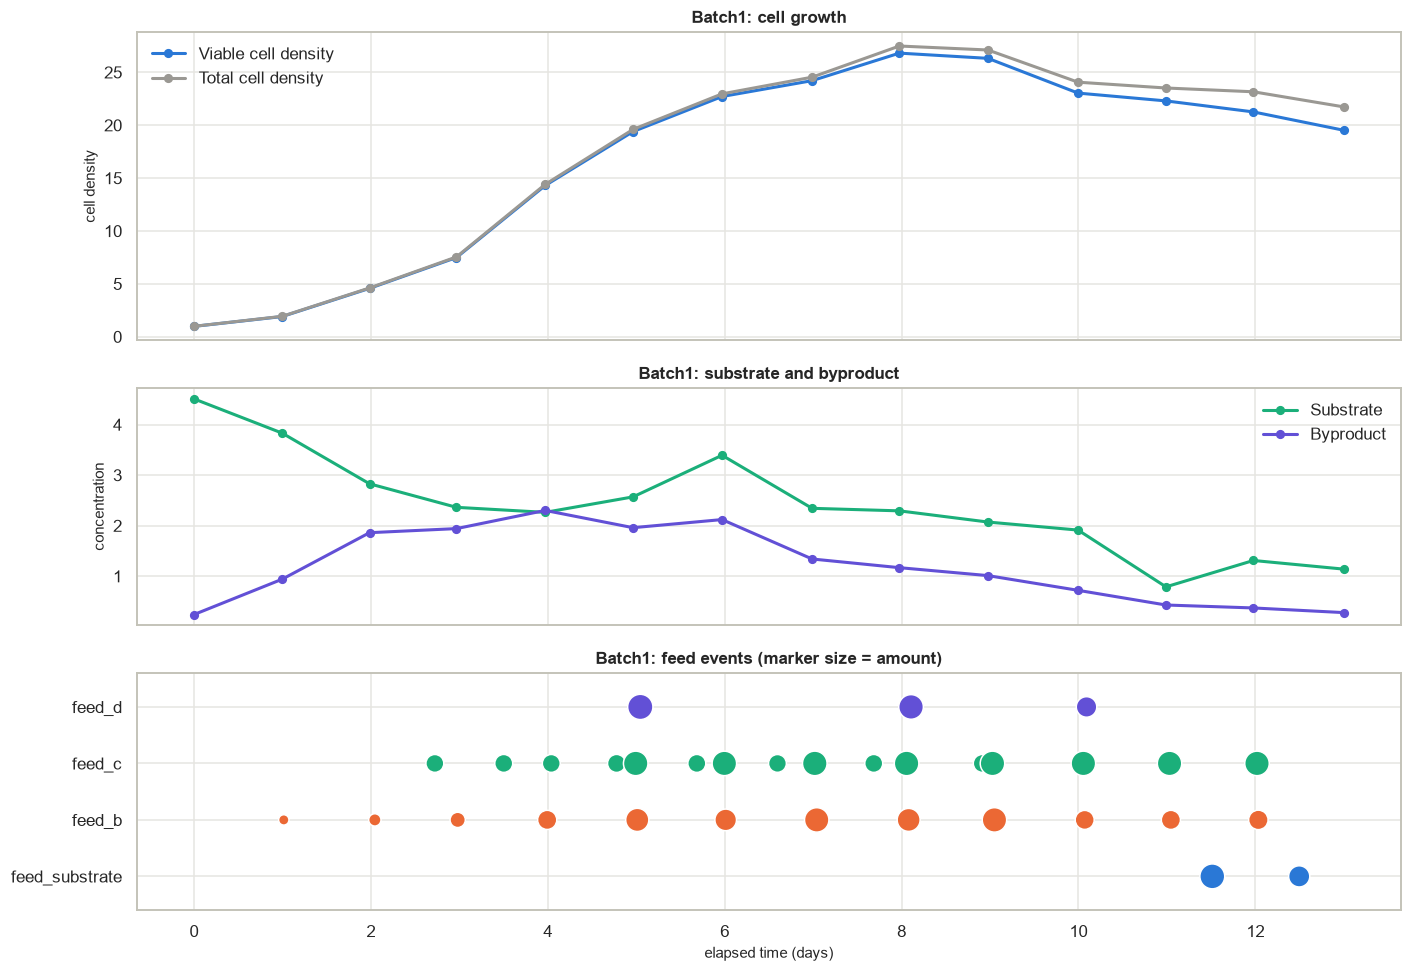

In [4]:
b = raw[raw.batch_id == "Batch1"]
fig, axes = plt.subplots(3, 1, figsize=(13, 9), sharex=True, gridspec_kw={"height_ratios": [1.3, 1, 1]})

ax = axes[0]
s = b.dropna(subset=["vcd"])
for col, c in zip(["vcd", "tcd"], [TRAIN, "#9a9893"]):
    ax.plot(s.elapsed_time, s[col], marker="o", ms=5, color=c, label=LABELS[col])
ax.set_ylabel("cell density"); ax.set_title("Batch1: cell growth")
ax.legend(frameon=False, loc="upper left")

ax = axes[1]
for col, c in zip(["substrate", "byproduct"], [ACCENT, "#6250d6"]):
    ax.plot(s.elapsed_time, s[col], marker="o", ms=5, color=c, label=LABELS[col])
ax.set_ylabel("concentration"); ax.set_title("Batch1: substrate and byproduct")
ax.legend(frameon=False, loc="upper right")

ax = axes[2]
for i, f in enumerate(FEEDS):
    ev = b.dropna(subset=[f])
    sizes = 30 + 250 * ev[f] / raw[f].max()
    ax.scatter(ev.elapsed_time, np.full(len(ev), i), s=sizes, color=FEED_COLORS[f], edgecolor="white", linewidth=1)
ax.set_yticks(range(4), FEEDS); ax.set_ylim(-0.6, 3.6)
ax.set_title("Batch1: feed events (marker size = amount)")
ax.set_xlabel("elapsed time (days)")
plt.tight_layout(); plt.show()

## 4. State trajectories across all training batches

Each thin line is one training batch; the bold line is the median across batches at each day.

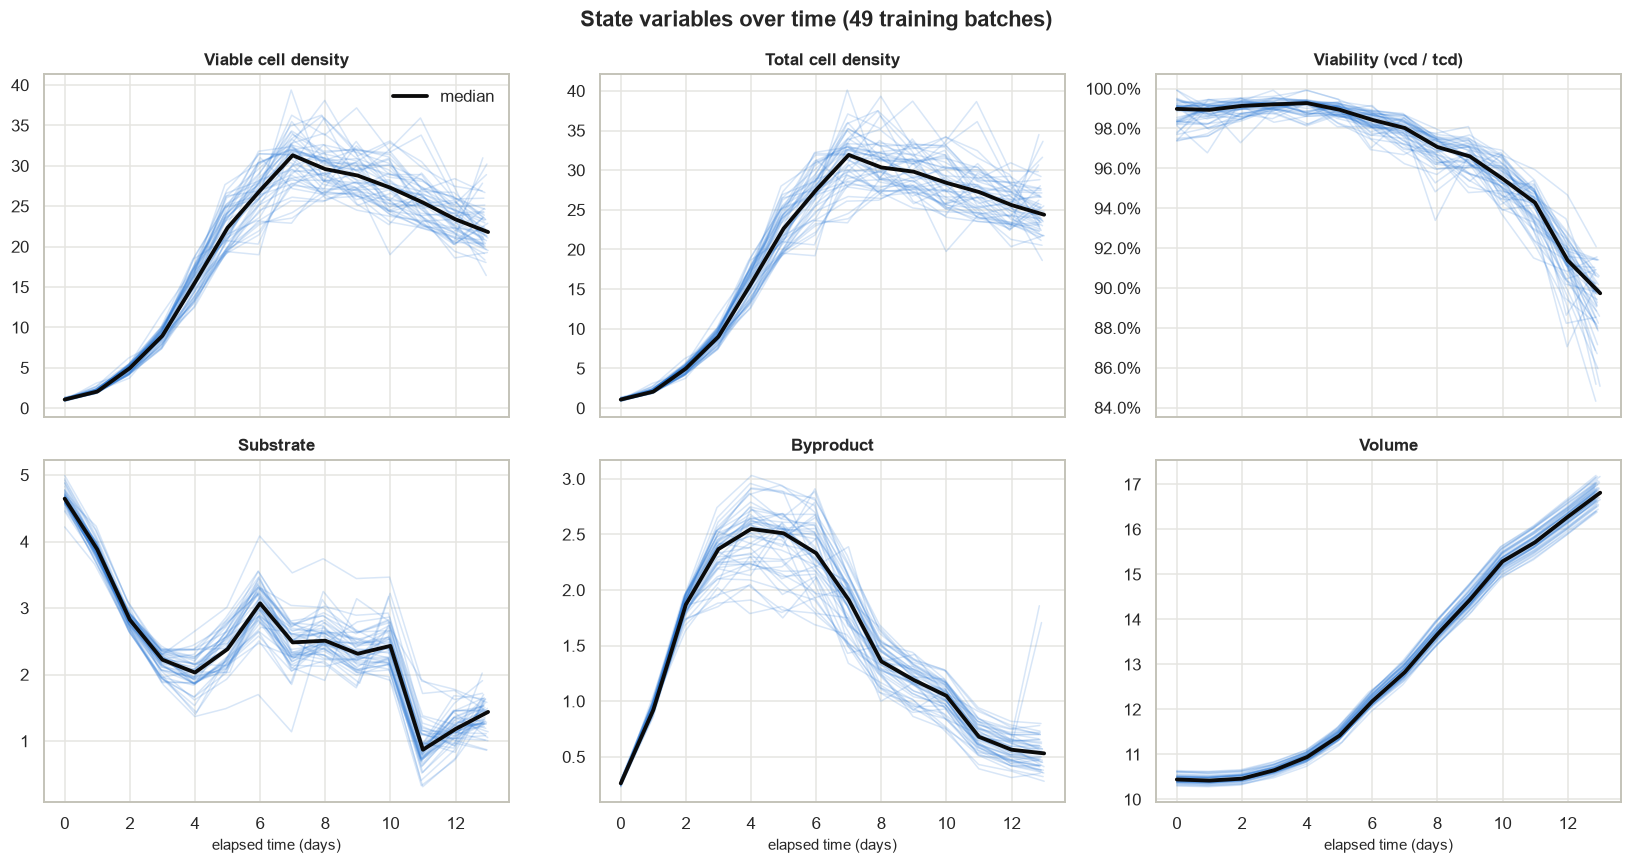

In [5]:
train_s = raw[(raw.split == "train") & raw.vcd.notna()].copy()
train_s["viability"] = train_s.vcd / train_s.tcd
train_s["day"] = train_s.elapsed_time.round().astype(int)

vars_ = ["vcd", "tcd", "viability", "substrate", "byproduct", "volume"]
fig, axes = plt.subplots(2, 3, figsize=(15, 8), sharex=True)
for ax, v in zip(axes.flat, vars_):
    for _, g in train_s.groupby("batch_id"):
        ax.plot(g.elapsed_time, g[v], color=TRAIN, alpha=0.18, linewidth=1)
    med = train_s.groupby("day")[v].median()
    ax.plot(med.index, med.values, color="#0b0b0b", linewidth=2.5, label="median")
    ax.set_title(LABELS[v])
    if v == "viability":
        ax.yaxis.set_major_formatter(mticker.PercentFormatter(1.0))
for ax in axes[1]: ax.set_xlabel("elapsed time (days)")
axes[0, 0].legend(frameon=False)
fig.suptitle(f"State variables over time ({train_s.batch_id.nunique()} training batches)", fontweight="bold")
plt.tight_layout(); plt.show()

### Spread at each day

Boxplots show how much batches diverge as the run progresses: the spread is what a model has to explain.

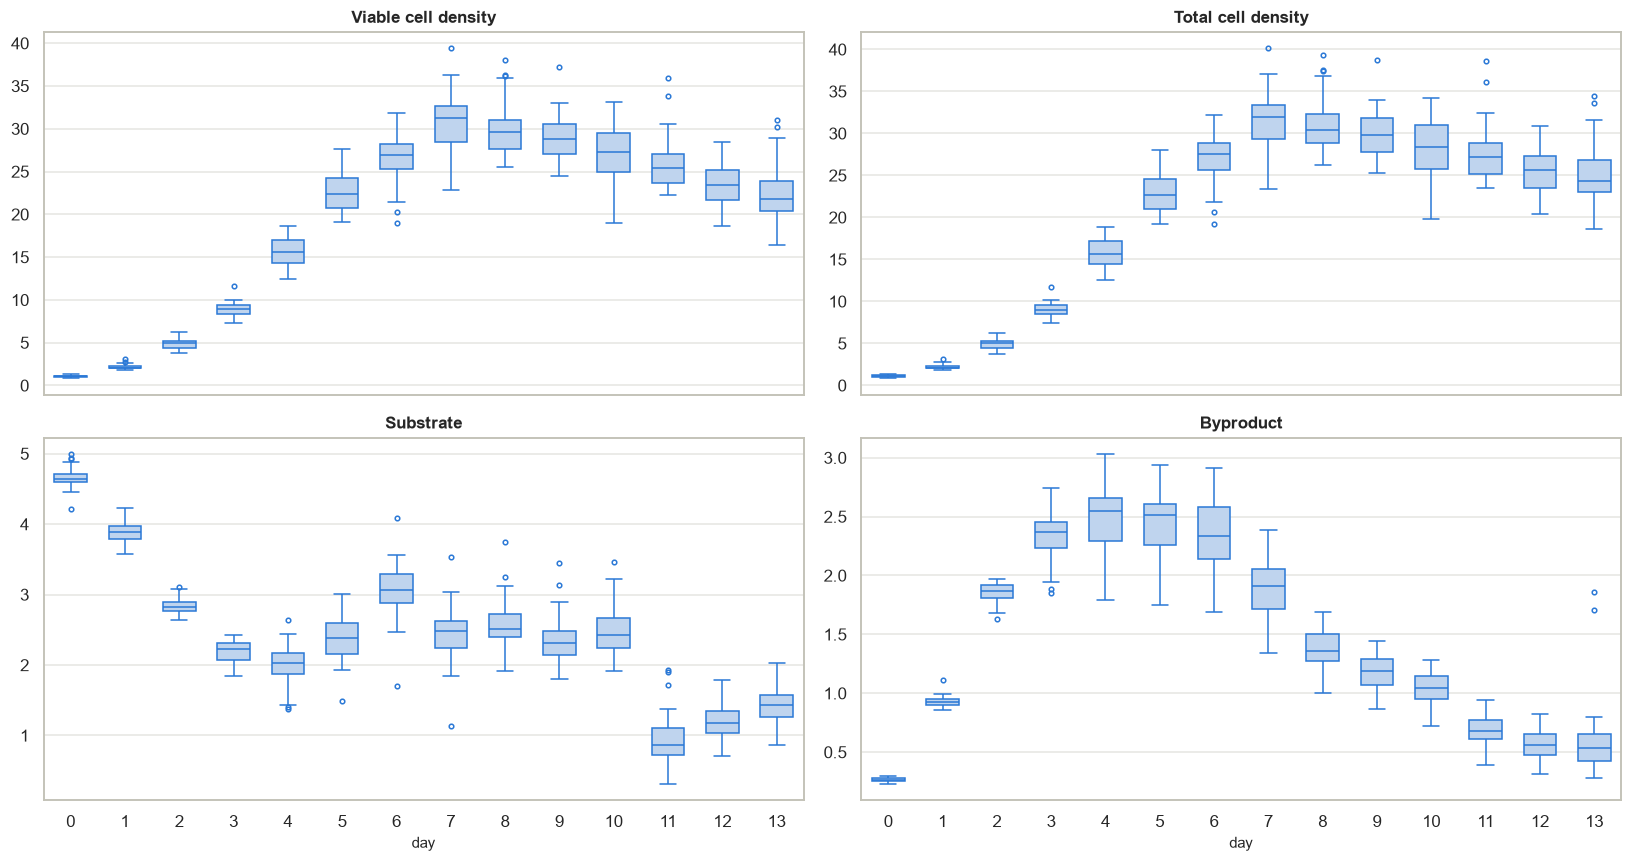

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(15, 8), sharex=True)
for ax, v in zip(axes.flat, STATE):
    sns.boxplot(data=train_s, x="day", y=v, ax=ax, color="#b7d3f6", linecolor=TRAIN,
                fliersize=3, width=0.6)
    ax.set_title(LABELS[v]); ax.set_ylabel(""); ax.grid(axis="x", visible=False)
for ax in axes[1]: ax.set_xlabel("day")
plt.tight_layout(); plt.show()

## 5. Feeds

The four feeds follow different schedules:

- `feed_b`: one bolus per day from day 1 to 12. The dose ramps up to ~0.9 by day 7-9, then drops to ~0.5.
- `feed_c`: small doses from day ~2 on, in two fixed sizes (~0.00085 and ~0.0018). The number of events varies a lot between batches.
- `feed_d`: exactly three additions, on days 5, 8 and 10.
- `feed_substrate`: 2-3 additions, almost always at day ~11.5 and ~12.5 (a few batches get one earlier).

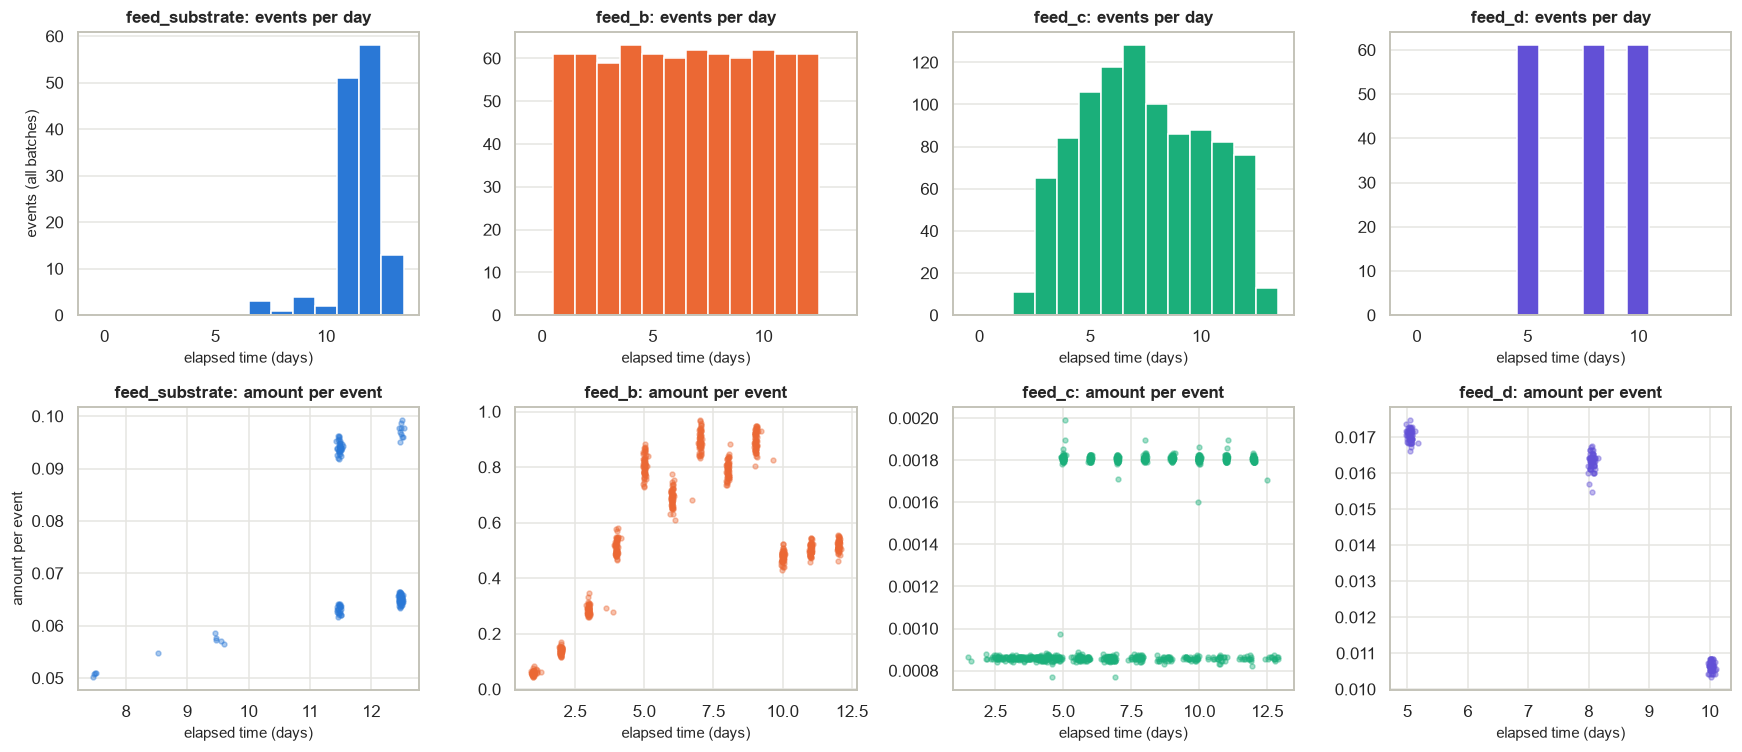

Feed events per batch (min / median / max):
                min  median  max
feed                            
feed_b           12      12   12
feed_c           11      14   35
feed_d            3       3    3
feed_substrate    2       2    3


In [7]:
feeds = raw.melt(id_vars=["batch_id", "elapsed_time", "split"], value_vars=FEEDS,
                 var_name="feed", value_name="amount").dropna(subset=["amount"])

fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for i, f in enumerate(FEEDS):
    d = feeds[feeds.feed == f]
    ax = axes[0, i]
    ax.hist(d.elapsed_time, bins=np.arange(-0.5, 13.6, 1), color=FEED_COLORS[f], edgecolor="white")
    ax.set_title(f"{f}: events per day"); ax.set_xlabel("elapsed time (days)")
    if i == 0: ax.set_ylabel("events (all batches)")
    ax.grid(axis="x", visible=False)

    ax = axes[1, i]
    ax.scatter(d.elapsed_time, d.amount, s=10, alpha=0.4, color=FEED_COLORS[f])
    ax.set_title(f"{f}: amount per event"); ax.set_xlabel("elapsed time (days)")
    if i == 0: ax.set_ylabel("amount per event")
plt.tight_layout(); plt.show()

per_batch = feeds.groupby(["batch_id", "feed"]).size().unstack()
print("Feed events per batch (min / median / max):")
print(per_batch.agg(["min", "median", "max"]).T.astype(int).to_string())

### Cumulative feed per batch

Total amount fed over time, per batch. Train and test batches use the same feeding regimes,
which is what makes the test trajectories predictable.

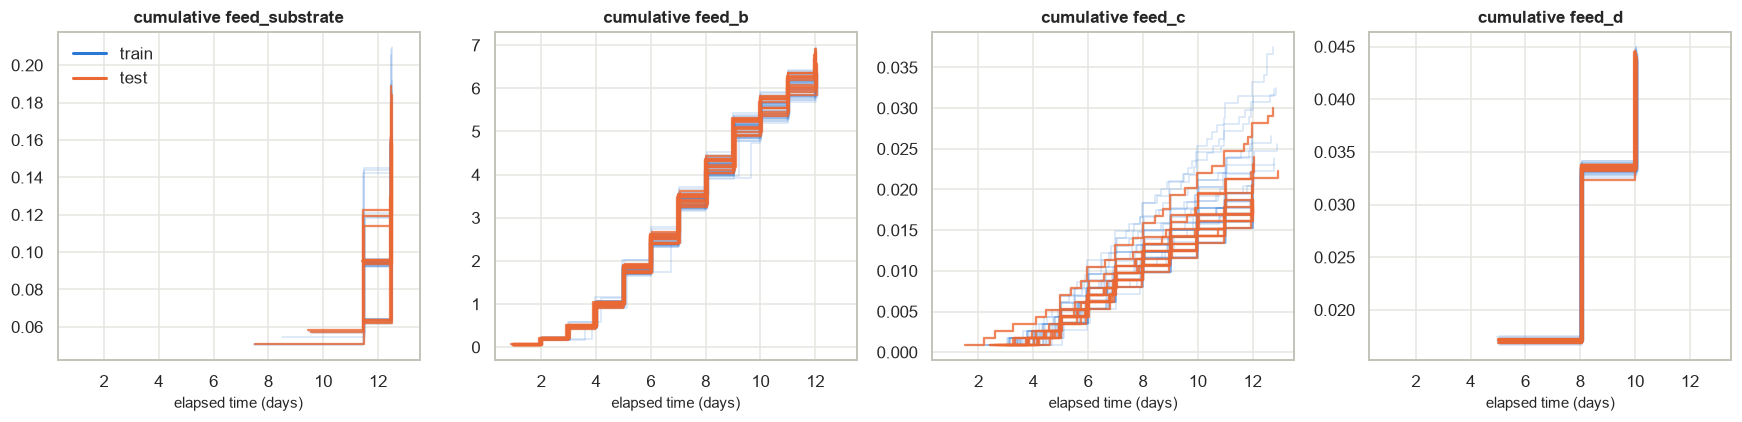

In [8]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4), sharex=True)
for ax, f in zip(axes, FEEDS):
    groups = sorted(raw.dropna(subset=[f]).groupby(["batch_id", "split"]), key=lambda kv: kv[0][1] == "test")
    for (bid, split), g in groups:
        ax.step(g.elapsed_time, g[f].cumsum(), where="post",
                color=TEST if split == "test" else TRAIN,
                alpha=0.8 if split == "test" else 0.2, linewidth=1.5 if split == "test" else 1)
    ax.set_title(f"cumulative {f}"); ax.set_xlabel("elapsed time (days)")
axes[0].plot([], [], color=TRAIN, label="train"); axes[0].plot([], [], color=TEST, label="test")
axes[0].legend(frameon=False)
plt.tight_layout(); plt.show()

## 5b. Feeding identifier: how many feeding regimens are there?

**Hypothesis:** the batches test different feeding regimens, and the resulting VCD/TCD differ because of them.

**Strategies to find the regimens**

1. **Rule-based signature (used below):** look for feeds whose dose or timing takes *discrete* values across
   batches (e.g. a low vs high dose, a dose that only some batches get) and combine them into a label.
   This is transparent and gives exact group counts.
2. **Clustering on a per-batch feed profile:** build one vector per batch (dose per day for each feed), standardise
   it, and cluster (k-means / hierarchical). Use the silhouette score to judge whether real groups exist.
   This finds continuous "recipe" differences that a rule would miss.
3. **Check designed vs reactive:** a dose that depends on a *preceding measurement* is a control action, not a
   design choice. Compare each dose decision with the sample taken just before it. If a threshold
   separates them perfectly, the "regimen" is really the process reacting to its own state.

The cells below run all three. The short version:

| Feed | Varies between batches? | Nature |
|---|---|---|
| `feed_b` | dose ±5% around one shared daily recipe, no discrete levels | same recipe + noise (weakly follows VCD) |
| `feed_d` | identical schedule and dose in every batch (days 5, 8, 10) | fixed |
| `feed_c` | 8 large doses fixed in every batch, plus 3-27 small doses at irregular times | count varies continuously; only weakly linked to cell state (origin unclear) |
| `feed_substrate` | **discrete**: optional early dose, and low/high doses at day 11.5 and 12.5 | **triggered by the measured substrate** |

So the only discrete feeding difference between batches is the `feed_substrate` pattern, and it follows a
threshold rule on the substrate measurement. The identifier below is built from that pattern.

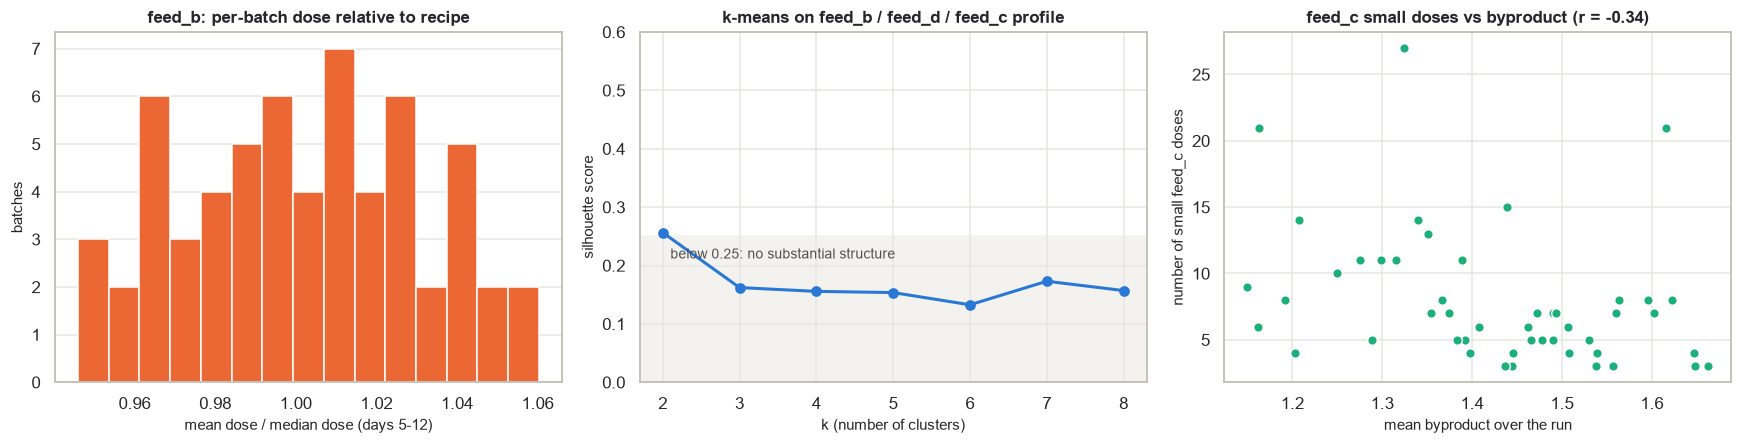

silhouette by k: {2: 0.26, 3: 0.16, 4: 0.16, 5: 0.15, 6: 0.13, 7: 0.17, 8: 0.16}


In [9]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

# --- per-batch feed profile (strategy 2) ---
fe = raw.dropna(subset=["feed_b"]).assign(day=lambda x: x.elapsed_time.round().astype(int))
fb = fe.pivot_table(index="batch_id", columns="day", values="feed_b")
fb = fb.fillna(fb.median())                                      # a few missing days -> day median
fd = raw.dropna(subset=["feed_d"]).assign(day=lambda x: x.elapsed_time.round().astype(int)) \
        .pivot_table(index="batch_id", columns="day", values="feed_d")
fc = raw.dropna(subset=["feed_c"])
fc_small = fc[fc.feed_c < 0.0013].groupby("batch_id").size().rename("feed_c_n_small")
profile = pd.concat([fb.add_prefix("feed_b_d"), fd.add_prefix("feed_d_d"), fc_small], axis=1).fillna(0)

X = StandardScaler().fit_transform(profile)
sil = {k: silhouette_score(X, KMeans(k, n_init=20, random_state=0).fit_predict(X)) for k in range(2, 9)}

fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
ax = axes[0]
scale = (fb / fb.median()).loc[:, 5:].mean(axis=1)
ax.hist(scale, bins=15, color=FEED_COLORS["feed_b"], edgecolor="white")
ax.set_title("feed_b: per-batch dose relative to recipe")
ax.set_xlabel("mean dose / median dose (days 5-12)"); ax.set_ylabel("batches"); ax.grid(axis="x", visible=False)

ax = axes[1]
ax.plot(list(sil), list(sil.values()), marker="o", color=TRAIN)
ax.axhspan(0, 0.25, color="#f3f2ef", zorder=0)
ax.text(2.1, 0.23, "below 0.25: no substantial structure", fontsize=9, color="#52514e", va="top")
ax.set_ylim(0, 0.6); ax.set_xlabel("k (number of clusters)"); ax.set_ylabel("silhouette score")
ax.set_title("k-means on feed_b / feed_d / feed_c profile")

ax = axes[2]
small = fc_small.reindex(raw.batch_id.unique()).fillna(0)
mean_byp = raw[raw.vcd.notna() & (raw.split == "train")].groupby("batch_id").byproduct.mean()
jj = pd.concat([small, mean_byp], axis=1).dropna()
ax.scatter(jj.byproduct, jj.feed_c_n_small, s=40, color=FEED_COLORS["feed_c"], edgecolor="white")
ax.set_xlabel("mean byproduct over the run"); ax.set_ylabel("number of small feed_c doses")
ax.set_title(f"feed_c small doses vs byproduct (r = {jj.corr().iloc[0, 1]:.2f})")
plt.tight_layout(); plt.show()
print("silhouette by k:", {k: round(v, 2) for k, v in sil.items()})

`feed_b` has one continuous spread of about ±5% and no discrete dose levels. Clustering finds no real groups:
the best score (k = 2, silhouette ≈ 0.26) only splits batches into "slightly lower" vs "slightly higher" `feed_b`,
which cuts one continuous spread in half. Small `feed_c` doses vary in number but are only weakly
(and negatively) related to the cell state. The clearly discrete structure is in `feed_substrate`:

In [10]:
# --- feed_substrate signature (strategy 1) ---
day_sample = raw[raw.vcd.notna()].assign(day=lambda x: x.elapsed_time.round().astype(int)) \
                .pivot_table(index="batch_id", columns="day", values="substrate")

rows = []
for bid, g in raw.dropna(subset=["feed_substrate"]).groupby("batch_id"):
    early, late = g[g.elapsed_time < 11], g[g.elapsed_time >= 11].sort_values("elapsed_time")
    rows.append({
        "batch_id": bid,
        "split": raw.loc[raw.batch_id == bid, "split"].iloc[0],
        "early_dose_day": round(early.elapsed_time.iloc[0], 1) if len(early) else np.nan,
        "dose_d11_5": late.feed_substrate.iloc[0],
        "dose_d12_5": late.feed_substrate.iloc[1],
    })
fs = pd.DataFrame(rows).set_index("batch_id")
fs["d11"] = np.where(fs.dose_d11_5 > 0.08, "H", "L")
fs["d12"] = np.where(fs.dose_d12_5 > 0.08, "H", "L")
fs["early"] = np.where(fs.early_dose_day.notna(), "early dose", "no early dose")
fs["regimen"] = fs.early + " · " + fs.d11 + fs.d12
fs = fs.join(day_sample[[11, 12]].rename(columns={11: "substrate_d11", 12: "substrate_d12"}))

REGIMENS = fs.regimen.value_counts().index.tolist()          # largest group first
REG_COLORS = dict(zip(REGIMENS, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]))

summary = fs.groupby("regimen").agg(batches=("split", "size"), test_batches=("split", lambda s: (s == "test").sum()),
                                    early_dose_days=("early_dose_day", lambda s: ", ".join(sorted({f"{v:.1f}" for v in s.dropna()})) or "-"))
print(f"{len(REGIMENS)} feeding identifiers (H = high dose ~0.095, L = low dose ~0.064, at day 11.5 / 12.5)")
summary.loc[REGIMENS]

6 feeding identifiers (H = high dose ~0.095, L = low dose ~0.064, at day 11.5 / 12.5)


,batches,test_batches,early_dose_days
regimen,,,
no early dose · HL,31,5,-
no early dose · LL,10,2,-
early dose · LL,7,3,"7.5, 8.5, 9.5, 9.6"
no early dose · LH,7,2,-
no early dose · HH,3,0,-
early dose · HL,3,0,7.5


### Is the `feed_substrate` pattern designed, or triggered by the substrate? (strategy 3)

Each late dose is plotted against the substrate measured in the sample just before it (day 11 and day 12).

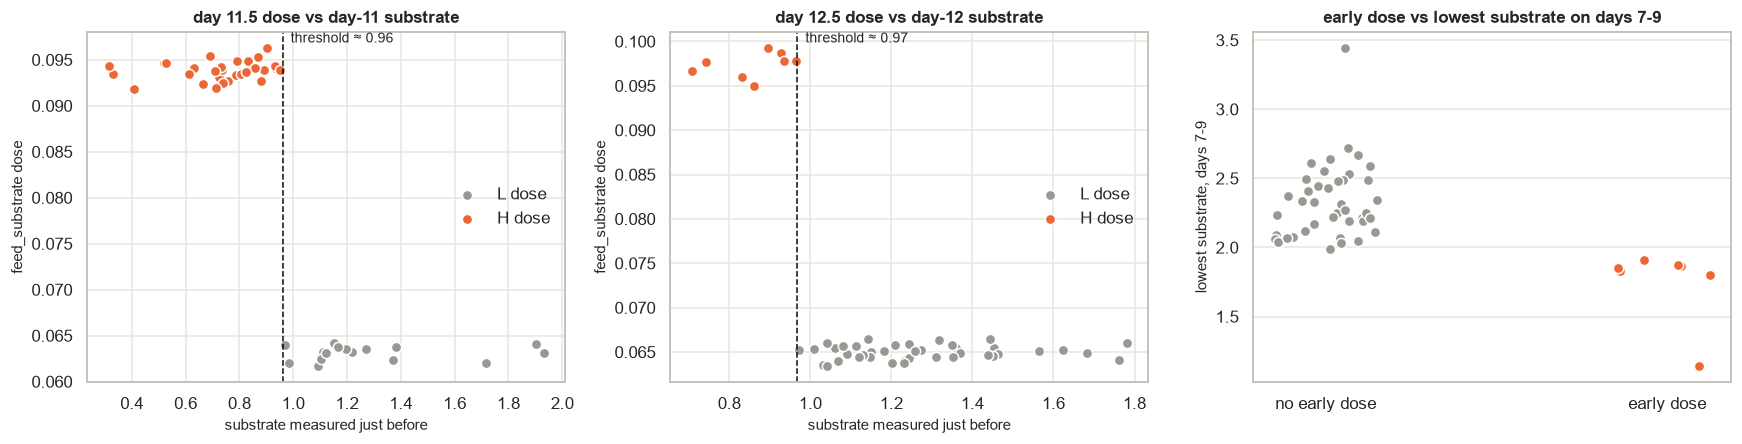

In [11]:
tr_fs = fs[fs.split == "train"]
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
for ax, (col, dose, lvl, title) in zip(axes[:2], [("substrate_d11", "dose_d11_5", "d11", "day 11.5 dose vs day-11 substrate"),
                                                  ("substrate_d12", "dose_d12_5", "d12", "day 12.5 dose vs day-12 substrate")]):
    for level, c in [("L", "#9a9893"), ("H", TEST)]:
        d = tr_fs[tr_fs[lvl] == level]
        ax.scatter(d[col], d[dose], s=45, color=c, edgecolor="white", label=f"{level} dose")
    thr = (tr_fs.loc[tr_fs[lvl] == "H", col].max() + tr_fs.loc[tr_fs[lvl] == "L", col].min()) / 2
    ax.axvline(thr, color="#0b0b0b", linestyle="--", linewidth=1)
    ax.text(thr, ax.get_ylim()[1], f"  threshold ≈ {thr:.2f}", va="top", fontsize=9)
    ax.set_xlabel("substrate measured just before"); ax.set_ylabel("feed_substrate dose"); ax.set_title(title)
    ax.legend(frameon=False, loc="center right")

ax = axes[2]
pre = day_sample.loc[tr_fs.index, [7, 8, 9]].min(axis=1)
for has, c, lab in [(False, "#9a9893", "no early dose"), (True, TEST, "early dose")]:
    sel = tr_fs.early_dose_day.notna() == has
    ax.scatter(np.random.default_rng(0).uniform(-0.15, 0.15, sel.sum()) + has, pre[sel], s=45, color=c, edgecolor="white", label=lab)
ax.set_xticks([0, 1], ["no early dose", "early dose"]); ax.set_ylabel("lowest substrate, days 7-9")
ax.set_title("early dose vs lowest substrate on days 7-9"); ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()

**Result:** a high late dose is given exactly when the preceding substrate measurement is below ~0.96. Early doses
only happen in batches whose substrate dipped below ~2. So `feed_substrate` is a **feedback controller**,
not a designed regimen. The identifier is still useful for grouping (and the test batches carry it too, which tells you
whether their hidden substrate crossed those thresholds), but it describes the *outcome* of each batch, not an independent
treatment. Keep that in mind before reading VCD/TCD differences between groups as causal.

### Section 5, coloured by feeding identifier

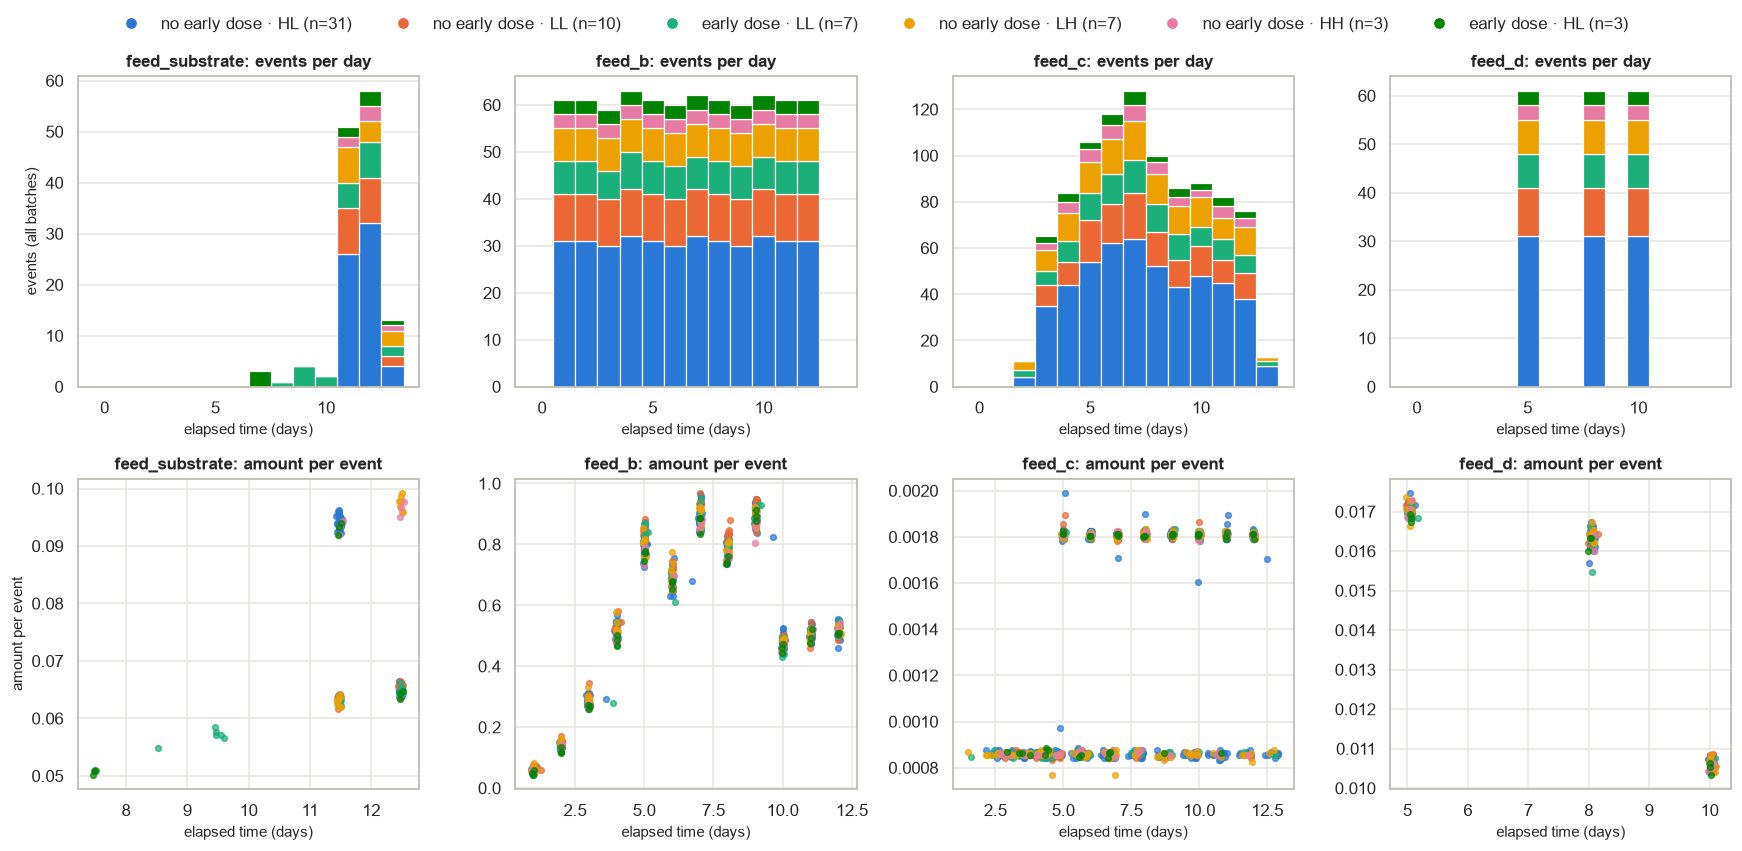

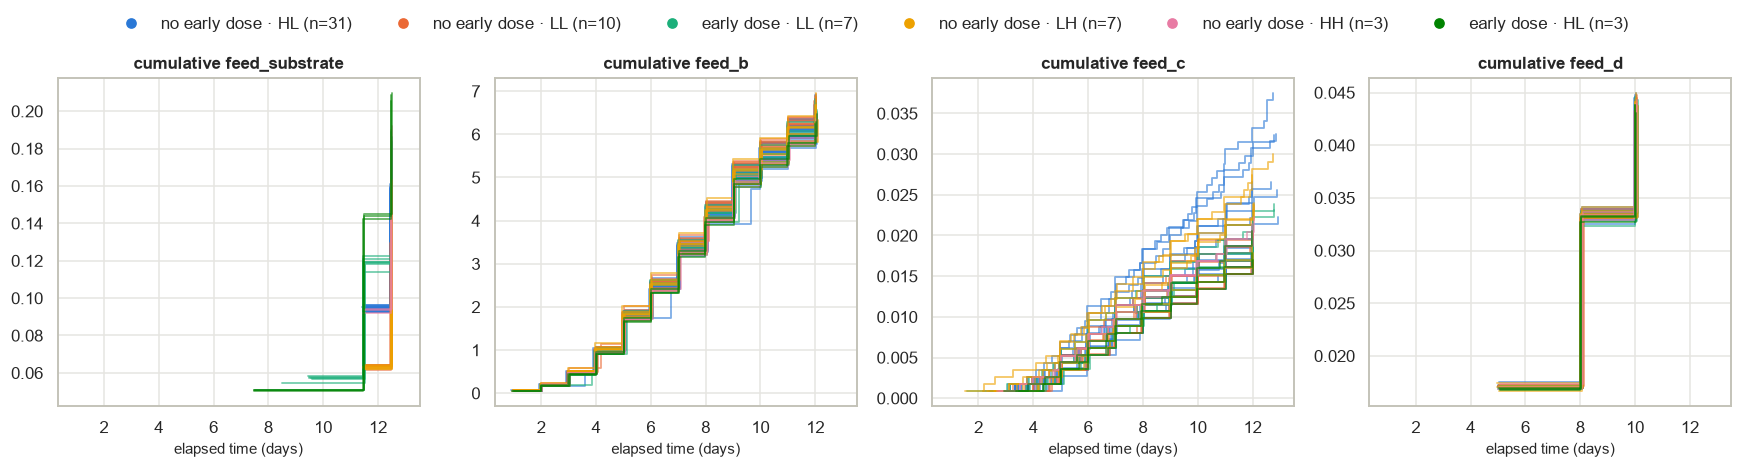

In [12]:
feeds_r = feeds.join(fs.regimen, on="batch_id")
raw_r = raw.join(fs.regimen, on="batch_id")

fig, axes = plt.subplots(2, 4, figsize=(16, 7.5))
for i, f in enumerate(FEEDS):
    d = feeds_r[feeds_r.feed == f]
    ax = axes[0, i]
    ax.hist([d.loc[d.regimen == g, "elapsed_time"] for g in REGIMENS], bins=np.arange(-0.5, 13.6, 1),
            stacked=True, color=[REG_COLORS[g] for g in REGIMENS], edgecolor="white", linewidth=0.8)
    ax.set_title(f"{f}: events per day"); ax.set_xlabel("elapsed time (days)"); ax.grid(axis="x", visible=False)
    if i == 0: ax.set_ylabel("events (all batches)")

    ax = axes[1, i]
    for g in REGIMENS:                                   # biggest group drawn first, small groups on top
        dd = d[d.regimen == g]
        ax.scatter(dd.elapsed_time, dd.amount, s=14, alpha=0.7, color=REG_COLORS[g])
    ax.set_title(f"{f}: amount per event"); ax.set_xlabel("elapsed time (days)")
    if i == 0: ax.set_ylabel("amount per event")
handles = [plt.Line2D([], [], marker="o", linestyle="", color=REG_COLORS[g], label=f"{g} (n={(fs.regimen == g).sum()})") for g in REGIMENS]
fig.legend(handles=handles, loc="upper center", ncol=len(REGIMENS), frameon=False, bbox_to_anchor=(0.5, 1.04))
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 4, figsize=(16, 4), sharex=True)
for ax, f in zip(axes, FEEDS):
    for g in REGIMENS:
        for bid, gg in raw_r[(raw_r.regimen == g)].dropna(subset=[f]).groupby("batch_id"):
            ax.step(gg.elapsed_time, gg[f].cumsum(), where="post", color=REG_COLORS[g], alpha=0.6, linewidth=1.2)
    ax.set_title(f"cumulative {f}"); ax.set_xlabel("elapsed time (days)")
fig.legend(handles=handles, loc="upper center", ncol=len(REGIMENS), frameon=False, bbox_to_anchor=(0.5, 1.08))
plt.tight_layout(); plt.show()

### Resulting VCD and TCD per feeding identifier

One panel per group (training batches only, since test batches have no measurements). Grey lines are all training
batches for reference; coloured lines are the group's batches and the bold line is the group median.

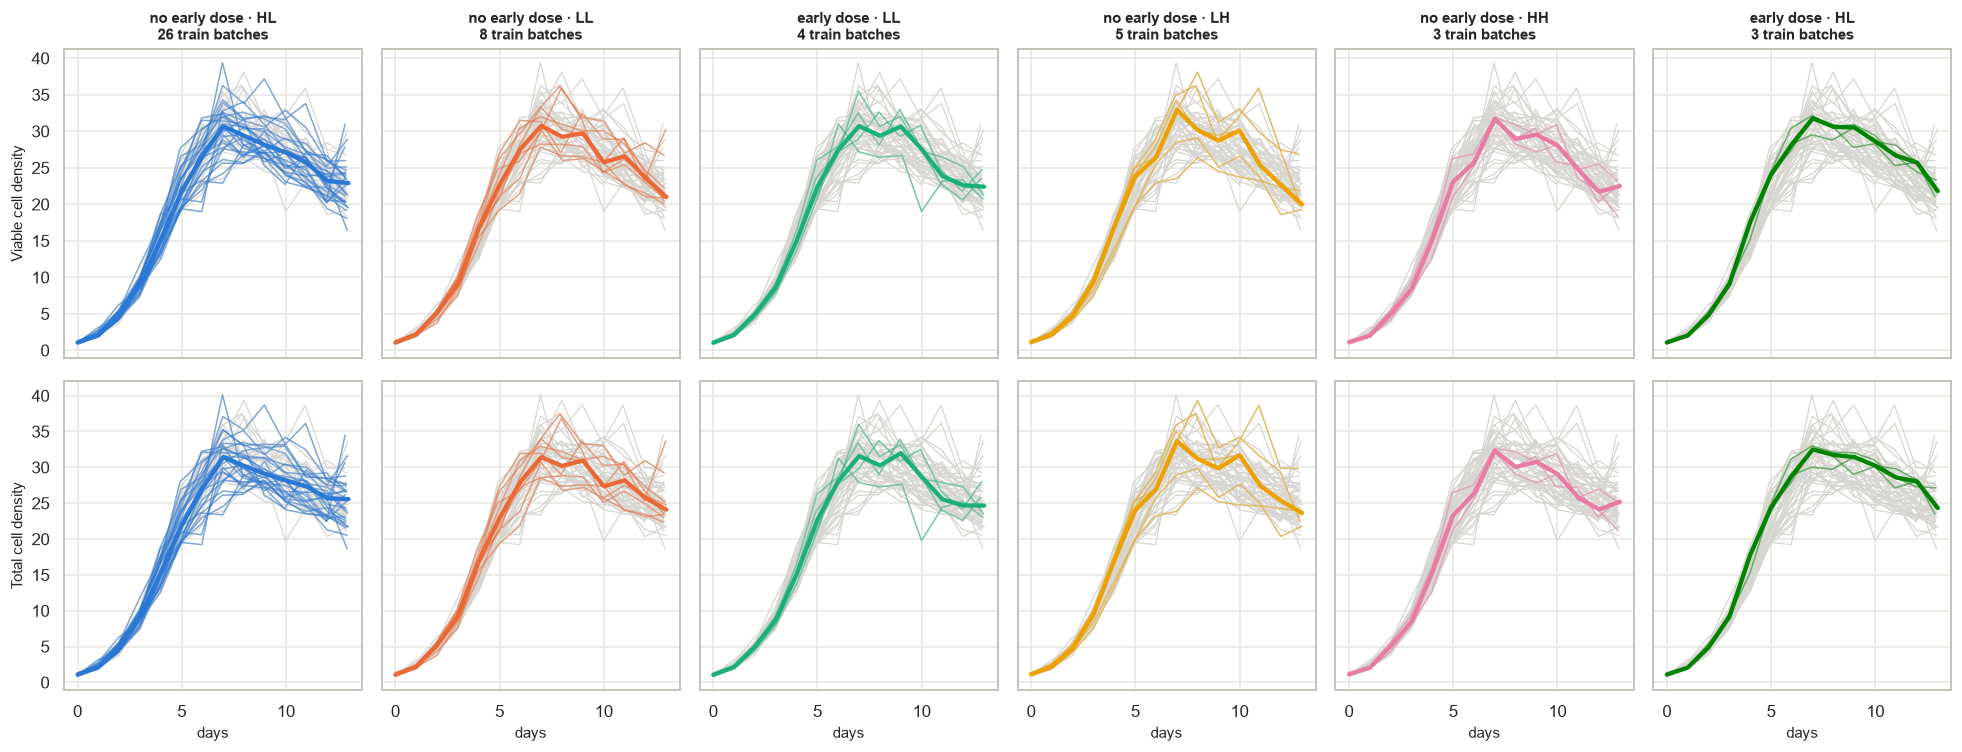

final_vcd      final_tcd      peak_vcd      peak_tcd     
                        mean  std      mean  std     mean  std     mean  std
regimen                                                                     
no early dose · HL      22.7  3.4      25.4  3.6     31.3  3.0     32.3  3.2
no early dose · LL      22.8  3.7      25.6  3.9     32.0  3.1     32.9  3.4
early dose · LL         22.6  1.9      25.1  2.3     33.0  1.8     33.7  1.9
no early dose · LH      21.6  3.1      24.3  3.2     32.8  4.9     34.0  5.4
no early dose · HH      21.3  2.6      23.9  2.4     31.7  0.1     32.3  0.3
early dose · HL         22.1  1.2      25.0  1.9     31.5  0.9     32.3  0.8

In [13]:
ts = train_s.join(fs.regimen, on="batch_id")
fig, axes = plt.subplots(2, len(REGIMENS), figsize=(18, 7), sharex=True, sharey="row")
for row, v in enumerate(["vcd", "tcd"]):
    for col, g in enumerate(REGIMENS):
        ax = axes[row, col]
        for _, b in ts.groupby("batch_id"):
            ax.plot(b.elapsed_time, b[v], color="#d6d5d0", linewidth=0.8)
        sub = ts[ts.regimen == g]
        for _, b in sub.groupby("batch_id"):
            ax.plot(b.elapsed_time, b[v], color=REG_COLORS[g], alpha=0.5, linewidth=1)
        if len(sub):
            med = sub.groupby("day")[v].median()
            ax.plot(med.index, med.values, color=REG_COLORS[g], linewidth=2.8)
        n_tr = sub.batch_id.nunique()
        if row == 0: ax.set_title(f"{g}\n{n_tr} train batches", fontsize=10)
        if col == 0: ax.set_ylabel(LABELS[v])
        if row == 1: ax.set_xlabel("days")
plt.tight_layout(); plt.show()

final = ts.sort_values("elapsed_time").groupby("batch_id").last()
peak = ts.groupby("batch_id")[["vcd", "tcd"]].max().add_prefix("peak_")
tab = final[["regimen", "vcd", "tcd"]].rename(columns={"vcd": "final_vcd", "tcd": "final_tcd"}).join(peak)
tab.groupby("regimen").agg(["mean", "std"]).round(1).loc[[g for g in REGIMENS if g in tab.regimen.values]]

**Reading this:** the groups barely differ in VCD/TCD. Group means for final and peak density lie within about 1.5 units
of each other, while batches *within* a group spread by about 2-4 units. Combined with the threshold plots above, this
data doesn't show distinct feeding regimens driving different growth. All batches follow one feeding recipe, and the
`feed_substrate` controller reacts to each batch's substrate level. If the organisers did vary something on purpose,
it isn't visible in the feed columns. It may sit in something not recorded here (e.g. the cell line or process
setpoints), or it may be the small continuous `feed_b` scaling.

In [14]:
# Batch -> feeding identifier lookup (all 61 batches, incl. test)
fs[["split", "regimen", "early_dose_day", "dose_d11_5", "dose_d12_5"]] \
    .sort_values(["regimen", "split"]).round(3)

,split,regimen,early_dose_day,dose_d11_5,dose_d12_5
batch_id,,,,,
Batch44,train,early dose · HL,7.5,0.094,0.065
Batch46,train,early dose · HL,7.5,0.093,0.064
Batch8,train,early dose · HL,7.5,0.092,0.063
Batch35,test,early dose · LL,9.6,0.062,0.064
Batch54,test,early dose · LL,9.5,0.064,0.066
...,...,...,...,...,...
Batch38,train,no early dose · LL,NaN,0.064,0.066
Batch39,train,no early dose · LL,NaN,0.062,0.064
Batch42,train,no early dose · LL,NaN,0.064,0.066


## 6. Distributions and relationships

Correlations below are pooled over all samples, so they are dominated by the shared time trend
(everything that moves with `elapsed_time` correlates with everything else). The scatter on the right
checks a per-batch relationship instead.

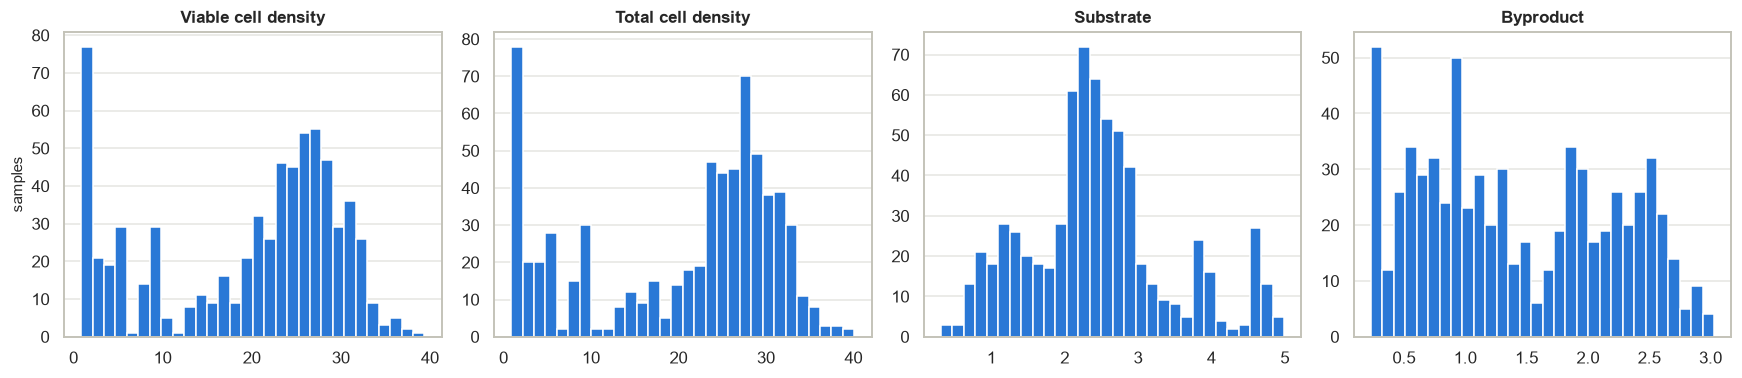

In [15]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.6))
for ax, v in zip(axes, STATE):
    ax.hist(train_s[v], bins=30, color=TRAIN, edgecolor="white")
    ax.set_title(LABELS[v]); ax.grid(axis="x", visible=False)
axes[0].set_ylabel("samples")
plt.tight_layout(); plt.show()

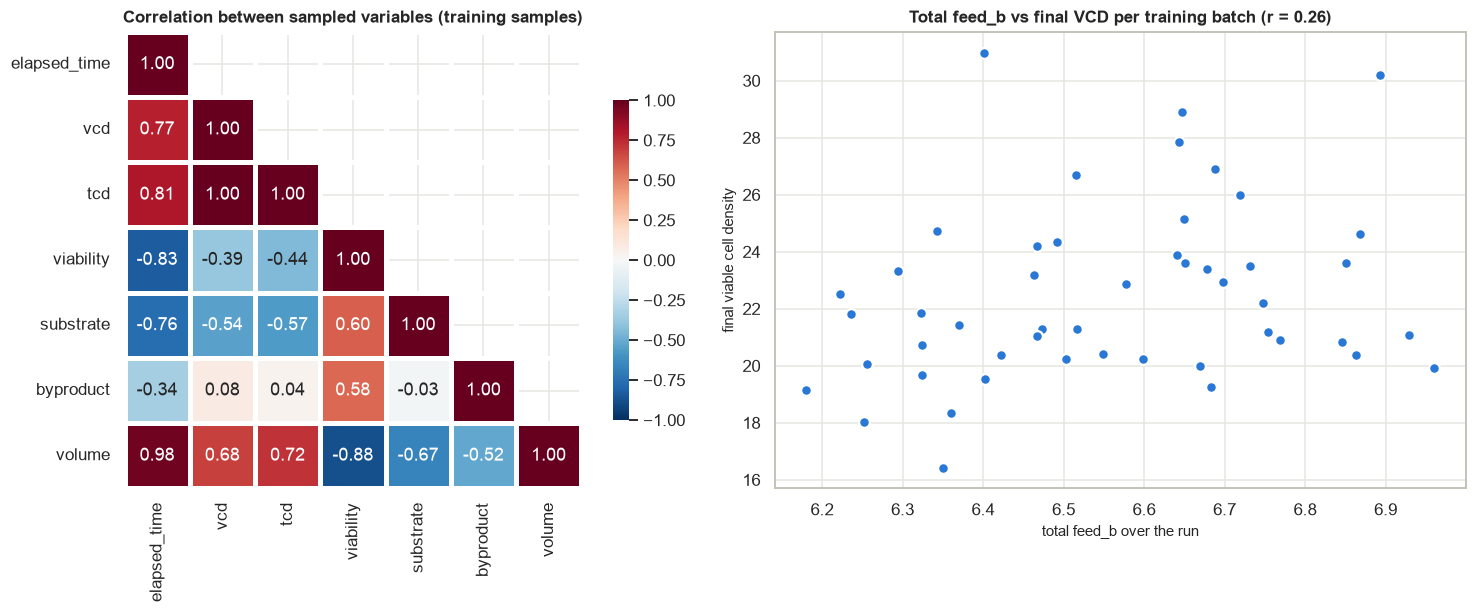

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), gridspec_kw={"width_ratios": [1, 1.1]})

corr = train_s[["elapsed_time", "vcd", "tcd", "viability", "substrate", "byproduct", "volume"]].corr()
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1,
            square=True, linewidths=2, linecolor="white", cbar_kws={"shrink": 0.7}, ax=axes[0])
axes[0].set_title("Correlation between sampled variables (training samples)")

# Does feeding explain final cell density?
total_feed = raw.groupby("batch_id")[FEEDS].sum()
final = train_s.sort_values("elapsed_time").groupby("batch_id").last()
joined = final[["vcd"]].join(total_feed)
ax = axes[1]
ax.scatter(joined.feed_b, joined.vcd, s=50, color=TRAIN, edgecolor="white", linewidth=1.5)
r = joined[["feed_b", "vcd"]].corr().iloc[0, 1]
ax.set_xlabel("total feed_b over the run"); ax.set_ylabel("final viable cell density")
ax.set_title(f"Total feed_b vs final VCD per training batch (r = {r:.2f})")
plt.tight_layout(); plt.show()

## 7. Are the test batches like the training batches?

The only measured state for a test batch is its day-0 sample. Comparing initial conditions and volume
trajectories shows whether the test set lies inside the training distribution.

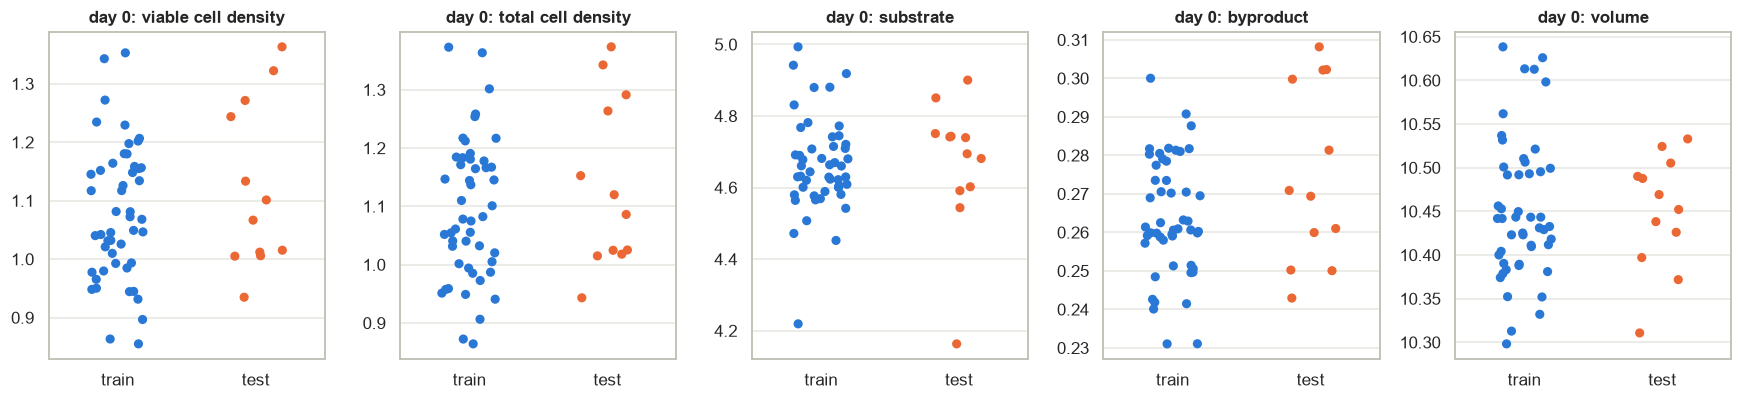

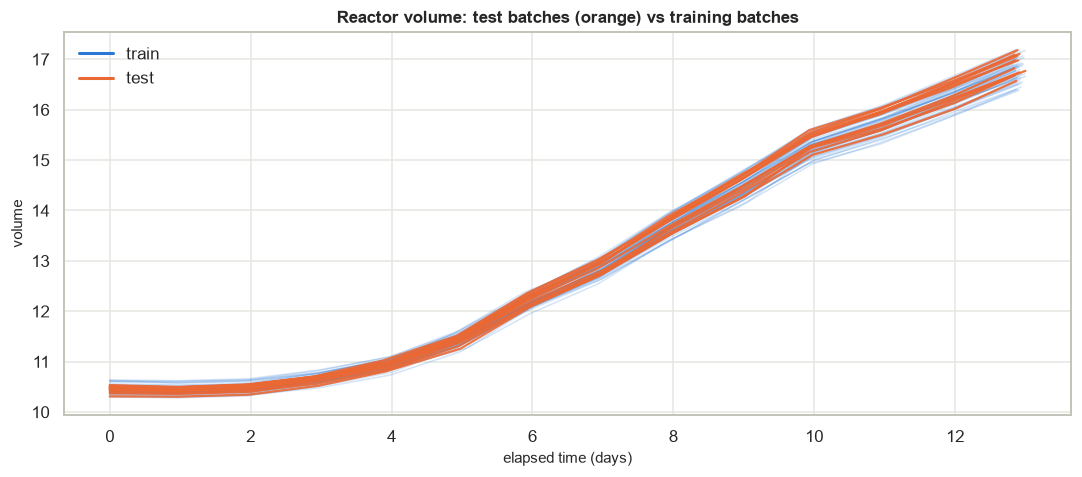

In [17]:
day0 = raw[(raw.elapsed_time < 0.05) & raw.vcd.notna()]
fig, axes = plt.subplots(1, 5, figsize=(16, 3.8))
for ax, v in zip(axes, STATE + ["volume"]):
    sns.stripplot(data=day0, x="split", y=v, hue="split", palette={"train": TRAIN, "test": TEST},
                  order=["train", "test"], size=6, jitter=0.2, ax=ax, legend=False)
    ax.set_title(f"day 0: {LABELS[v].lower()}"); ax.set_xlabel(""); ax.set_ylabel("")
    ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(10, 4.5))
groups = sorted(raw.dropna(subset=["volume"]).groupby(["batch_id", "split"]), key=lambda kv: kv[0][1] == "test")
for (bid, split), g in groups:
    ax.plot(g.elapsed_time, g.volume, color=TEST if split == "test" else TRAIN,
            alpha=0.9 if split == "test" else 0.2, linewidth=1.5 if split == "test" else 1)
ax.plot([], [], color=TRAIN, label="train"); ax.plot([], [], color=TEST, label="test")
ax.legend(frameon=False); ax.set_xlabel("elapsed time (days)"); ax.set_ylabel("volume")
ax.set_title("Reactor volume: test batches (orange) vs training batches")
plt.tight_layout(); plt.show()

## 8. Do the 61 batches form clusters that link test batches to training batches?

**Idea:** cluster all 61 batches, then train each test batch's model only on the training batches in its cluster.

**Constraint:** the 12 test batches only provide the day-0 sample, feeds and volume. So clusters have to be built
from those features. Clustering on full trajectories is possible for the 49, but test batches can't be placed in such clusters
unless day 0 + feeds predict them.

**Features per batch** (all available for test): log day-0 `vcd`/`tcd`/`substrate`/`byproduct`, start volume,
`feed_b` dose per day, number and total of `feed_c` doses, `feed_substrate` flags (early dose, day of early dose,
high dose at day 11.5 / 12.5), and volume added by each sample time. All are standardised on the 49 training batches.

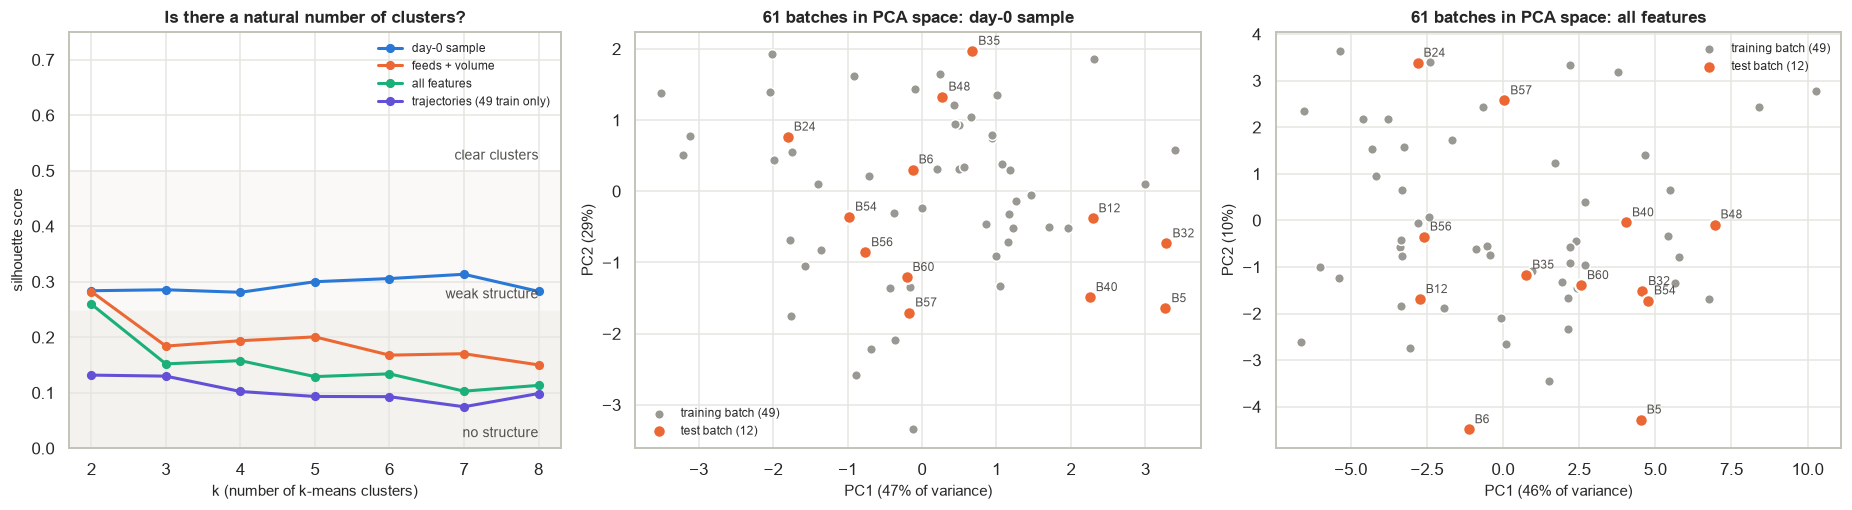

,day-0 sample,feeds + volume,all features,trajectories (49 train only)
2,0.28,0.28,0.26,0.13
3,0.29,0.18,0.15,0.13
4,0.28,0.19,0.16,0.10
5,0.30,0.20,0.13,0.09
6,0.31,0.17,0.13,0.09
7,0.31,0.17,0.10,0.07
8,0.28,0.15,0.11,0.10


In [18]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from scipy.spatial.distance import cdist

ids61 = sorted(raw.batch_id.unique(), key=lambda b: int(b[5:]))
train_ids = [b for b in ids61 if b not in test_batches]
d0 = raw[raw.vcd.notna() & (raw.elapsed_time < 0.05)].set_index("batch_id")

F = pd.DataFrame(index=ids61)
for v in STATE:
    F[f"log_{v}_d0"] = np.log(d0[v])
F["volume_d0"] = d0.volume
F = F.join(fb.add_prefix("feed_b_d"))                                   # feed_b dose per day (section 5b)
F["feed_c_n_small"] = fc_small.reindex(ids61).fillna(0)
F["feed_c_total"] = raw.groupby("batch_id").feed_c.sum()
F["early_dose"] = fs.early_dose_day.notna().astype(float)
F["early_dose_day"] = fs.early_dose_day.fillna(14)
F["high_d11_5"] = (fs.d11 == "H").astype(float)
F["high_d12_5"] = (fs.d12 == "H").astype(float)
vol = raw[raw.vcd.notna() | raw.to_predict].assign(day=lambda d: d.elapsed_time.round().astype(int)) \
         .pivot_table(index="batch_id", columns="day", values="volume")
for d in range(1, 14):
    F[f"volume_added_d{d}"] = vol[d] - F.volume_d0
F = F.fillna(F.median())

SETS = {"day-0 sample": [c for c in F if c.endswith("_d0")],
        "feeds + volume": [c for c in F if not c.endswith("_d0")],
        "all features": list(F.columns)}
Z = {name: (F[cols] - F.loc[train_ids, cols].mean()) / F.loc[train_ids, cols].std().replace(0, 1) for name, cols in SETS.items()}

sil = pd.DataFrame({name: {k: silhouette_score(z, KMeans(k, n_init=20, random_state=0).fit_predict(z)) for k in range(2, 9)}
                    for name, z in Z.items()})

# Clustering on the OUTCOME (full trajectories) of the 49 training batches
day = lambda d: d.assign(day=d.elapsed_time.round().astype(int))
traj = day(raw[raw.batch_id.isin(train_ids) & raw.vcd.notna() & (raw.elapsed_time > 0.5)])
T = pd.concat([np.log(traj.pivot_table(index="batch_id", columns="day", values=v)).sub(F.loc[train_ids, f"log_{v}_d0"], axis=0)
               .add_prefix(f"{v}_d") for v in STATE], axis=1)
Tz = (T - T.mean()) / T.std()
sil["trajectories (49 train only)"] = pd.Series({k: silhouette_score(Tz, KMeans(k, n_init=20, random_state=0).fit_predict(Tz)) for k in range(2, 9)})

fig, axes = plt.subplots(1, 3, figsize=(17, 4.8), gridspec_kw={"width_ratios": [1, 1.15, 1.15]})
ax = axes[0]
for (name, s_), c in zip(sil.items(), ["#2a78d6", "#eb6834", "#1baf7a", "#6250d6"]):
    ax.plot(s_.index, s_.values, marker="o", ms=5, color=c, label=name)
ax.axhspan(0, 0.25, color="#f3f2ef", zorder=0); ax.axhspan(0.25, 0.5, color="#faf9f7", zorder=0)
ax.text(8, 0.02, "no structure", ha="right", fontsize=9, color="#52514e")
ax.text(8, 0.27, "weak structure", ha="right", fontsize=9, color="#52514e")
ax.text(8, 0.52, "clear clusters", ha="right", fontsize=9, color="#52514e")
ax.set_ylim(0, 0.75); ax.set_xlabel("k (number of k-means clusters)"); ax.set_ylabel("silhouette score")
ax.set_title("Is there a natural number of clusters?"); ax.legend(frameon=False, fontsize=8, loc="upper right")

for ax, name in zip(axes[1:], ["day-0 sample", "all features"]):
    z = Z[name]
    U, S_, Vt = np.linalg.svd(z.loc[train_ids].values, full_matrices=False)   # PCA fitted on train
    pc = z.values @ Vt[:2].T
    expl = S_ ** 2 / np.sum(S_ ** 2)
    pcs = pd.DataFrame(pc, index=ids61, columns=["PC1", "PC2"])
    tr, te = pcs.loc[train_ids], pcs.loc[test_batches]
    ax.scatter(tr.PC1, tr.PC2, s=40, color="#9a9893", edgecolor="white", linewidth=1, label="training batch (49)")
    ax.scatter(te.PC1, te.PC2, s=70, color=TEST, edgecolor="white", linewidth=1.5, label="test batch (12)", zorder=3)
    for b, r in te.iterrows():
        ax.annotate(b.replace("Batch", "B"), (r.PC1, r.PC2), xytext=(4, 4), textcoords="offset points", fontsize=8, color="#52514e")
    ax.set_xlabel(f"PC1 ({expl[0]:.0%} of variance)"); ax.set_ylabel(f"PC2 ({expl[1]:.0%})")
    ax.set_title(f"61 batches in PCA space: {name}")
    ax.legend(frameon=False, fontsize=8, loc="best")
plt.tight_layout(); plt.show()
sil.round(2)

**Reading this:**

- **No clear clusters.** Every silhouette score stays below 0.32, with no peak that marks a natural k. In
  the PCA maps, the batches form one continuous cloud rather than separated groups.
- **Outcomes don't cluster either.** The 49 full trajectories score ≈ 0.13: batches differ by degree, not by type.
- **Test batches sit inside the training cloud.** Their distance to the nearest training batch is no larger than
  between training batches (table below), so no test batch needs extrapolation.

### Nearest training batches for each test batch

Even without clusters, *similarity* is well defined. These are the 5 closest training batches for each test batch
in the standardised all-feature space, with their feeding identifiers.

In [19]:
Zall = Z["all features"]
D = pd.DataFrame(cdist(Zall.loc[test_batches], Zall.loc[train_ids]), index=test_batches, columns=train_ids)
Dtt = cdist(Zall.loc[train_ids], Zall.loc[train_ids]); np.fill_diagonal(Dtt, np.inf)

rows = []
for b in test_batches:
    nn = D.loc[b].nsmallest(5)
    rows.append({"test batch": b, "feeding id": fs.regimen[b],
                 "5 nearest training batches": ", ".join(f"{n.replace('Batch', 'B')} ({d:.1f})" for n, d in nn.items()),
                 "same feeding id": f"{(fs.regimen[nn.index] == fs.regimen[b]).sum()}/5"})
print(f"median distance to nearest training batch: test {np.median(D.min(axis=1)):.2f} "
      f"vs training-to-training {np.median(Dtt.min(axis=1)):.2f}")
pd.DataFrame(rows).set_index("test batch")

median distance to nearest training batch: test 4.24 vs training-to-training 4.43


,feeding id,5 nearest training batches,same feeding id
test batch,,,
Batch5,no early dose · HL,"B15 (4.5), B4 (4.9), B31 (5.0), B27 (5.2), B50...",4/5
Batch6,early dose · LL,"B52 (5.5), B41 (6.3), B33 (6.3), B59 (6.7), B3...",3/5
Batch12,no early dose · HL,"B11 (4.5), B19 (4.7), B45 (4.8), B25 (5.2), B5...",4/5
Batch24,no early dose · LH,"B43 (3.3), B1 (4.5), B45 (4.9), B18 (5.1), B39...",1/5
Batch32,no early dose · LL,"B4 (4.0), B17 (4.4), B22 (4.6), B38 (4.8), B15...",1/5
Batch35,early dose · LL,"B52 (4.0), B59 (5.5), B58 (5.8), B41 (5.9), B3...",2/5
Batch40,no early dose · HL,"B17 (3.9), B4 (4.1), B22 (4.6), B37 (5.0), B34...",4/5
Batch48,no early dose · HL,"B15 (3.6), B27 (4.5), B38 (4.7), B2 (5.0), B16...",2/5
Batch54,early dose · LL,"B15 (6.0), B34 (6.2), B38 (6.3), B27 (6.4), B5...",1/5


### Does training on a cluster help prediction?

Tested in `model_playground` style on the team folds (pooled MAPE over the 637 held-out points). The ridge model predicts each
variable's log ratio to its day-0 value from the features above. For "per cluster", the batches are clustered within each
training fold, each held-out batch is assigned to its nearest cluster, and ridge is trained on that cluster only.

| Training strategy | vcd | tcd | substrate | byproduct | **mean** |
|---|---|---|---|---|---|
| **One global model (all 39-40 training batches)** | 7.69 | 7.65 | 9.08 | 10.41 | **8.71** |
| Global model + cluster id as an extra feature (k=3) | 7.73 | 7.66 | 9.17 | 10.36 | 8.73 |
| Per cluster, k=2 (all-feature clusters) | 8.18 | 8.17 | 10.50 | 10.65 | 9.37 |
| Per cluster, k=3 | 8.34 | 8.31 | 11.63 | 11.57 | 9.96 |
| Per cluster, k=4 | 8.98 | 8.99 | 11.41 | 12.52 | 10.48 |
| Nearest 10 batches (kNN-10) | 8.09 | 8.04 | 10.32 | 12.07 | 9.63 |
| Nearest 5 batches (kNN-5) | 8.92 | 8.87 | 10.91 | 11.64 | 10.09 |

The more the training data is split, the worse the score gets. Without real clusters, a per-cluster model only throws away
training batches (about 10-25 per cluster instead of ~40), which costs more than it gains. The global model already uses
similarity, because the features carry it: a batch with a low day-0 substrate gets a prediction shaped by other low-substrate batches.

## 9. Volume balance: is volume added that no feed records?

The feed columns are volumes, so the reactor volume should follow *start volume + all logged feeds*, minus what leaves
(sample withdrawals, evaporation). Any volume that enters without a logged feed shows up as a gap in this balance.

**Method.** Volume is recorded only at the daily samples (measured and hidden), never at feed events. So the balance is closed
per sampling interval, for all 61 batches:

$$\text{residual} = \Delta V_{\text{measured}} - \sum \text{feeds logged in the interval}$$

Withdrawals and evaporation make the residual **negative**. A **positive** residual means volume entered that no feed column records.


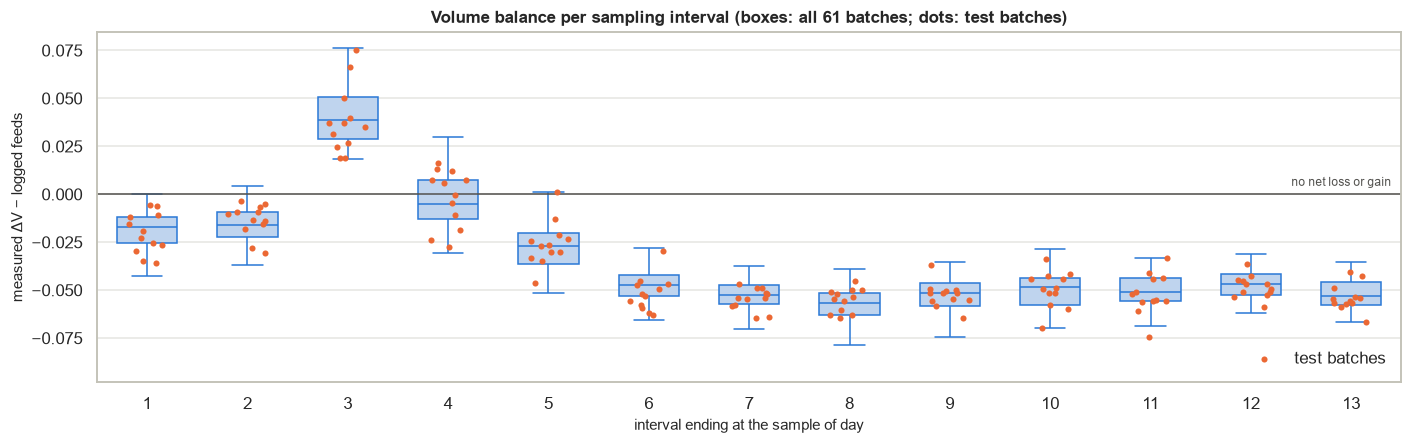

day,1,2,3,4,5,6,7,8,9,10,11,12,13
median,-0.017,-0.016,0.039,-0.005,-0.027,-0.047,-0.053,-0.057,-0.051,-0.048,-0.051,-0.047,-0.053
q25,-0.025,-0.023,0.029,-0.013,-0.036,-0.053,-0.057,-0.063,-0.058,-0.058,-0.055,-0.052,-0.058
q75,-0.012,-0.009,0.051,0.007,-0.020,-0.042,-0.047,-0.052,-0.046,-0.044,-0.044,-0.041,-0.046
share_positive,0.016,0.049,1.000,0.344,0.033,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000


In [20]:
rows = []
for bid, g in raw.sort_values("elapsed_time").groupby("batch_id"):
    s = g[g.volume.notna()]                                   # daily samples, incl. hidden test samples
    for (_, a), (_, c) in zip(s.iloc[:-1].iterrows(), s.iloc[1:].iterrows()):
        fed = g.loc[(g.elapsed_time > a.elapsed_time) & (g.elapsed_time <= c.elapsed_time), FEEDS].fillna(0).to_numpy().sum()
        rows.append({"batch_id": bid, "split": a.split, "day": int(round(c.elapsed_time)), "dV": c.volume - a.volume, "fed": fed})
vb = pd.DataFrame(rows).assign(residual=lambda d: d.dV - d.fed)

fig, ax = plt.subplots(figsize=(13, 4.2))
sns.boxplot(data=vb, x="day", y="residual", ax=ax, color="#b7d3f6", linecolor=TRAIN, fliersize=0, width=0.6)
sns.stripplot(data=vb[vb.split == "test"], x="day", y="residual", ax=ax, color=TEST, size=4, jitter=0.2, label="test batches")
ax.axhline(0, color="#52514e", linewidth=1)
ax.text(12.4, 0.003, "no net loss or gain", ha="right", va="bottom", fontsize=8, color="#52514e")
ax.set_xlabel("interval ending at the sample of day"); ax.set_ylabel("measured ΔV − logged feeds")
ax.set_title("Volume balance per sampling interval (boxes: all 61 batches; dots: test batches)")
h, l = ax.get_legend_handles_labels(); ax.legend(h[:1], l[:1], frameon=False, loc="lower right")
ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()

vb.groupby("day").residual.agg(median="median", q25=lambda r: r.quantile(0.25), q75=lambda r: r.quantile(0.75),
                               share_positive=lambda r: (r > 0).mean()).round(3).T


untracked addition, days 3-5: median 0.073 = 0.7% of the day-2 volume
share of batches with an addition: {'day 3': '100%', 'day 4': '84%', 'day 5': '23%'}


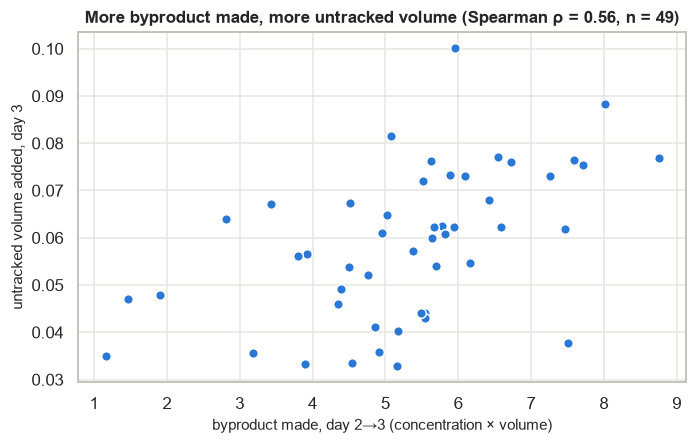

,day 3,day 4,days 3-5 total
split,,,
test,0.055,0.015,0.074
train,0.059,0.014,0.076


,Spearman ρ with the day-3 addition
"byproduct made, day 2→3",0.56
"byproduct peak, days 3-5",0.47
VCD at day 3,0.22


In [21]:
# Size of the addition: residual above each batch's own loss rate on days 1-2 (before lactate builds up)
R = vb.pivot(index="batch_id", columns="day", values="residual")
own_loss = R[[1, 2]].mean(axis=1)
added = pd.DataFrame({f"day {d}": R[d] - own_loss for d in (3, 4, 5)})
added["days 3-5 total"] = added.clip(lower=0).sum(axis=1)
added["split"] = raw.groupby("batch_id").split.first()
v_d2 = R.index.map(raw[raw.volume.notna() & raw.elapsed_time.between(1.5, 2.5)].groupby("batch_id").volume.first())
print(f"untracked addition, days 3-5: median {added['days 3-5 total'].median():.3f} "
      f"= {(added['days 3-5 total'] / v_d2).median():.1%} of the day-2 volume")
print("share of batches with an addition:", {c: f"{(added[c] > 0).mean():.0%}" for c in ["day 3", "day 4", "day 5"]})

# What does it track? Lactate (byproduct) made in the same interval, training batches only
w = {v: train_s.pivot_table(index="batch_id", columns="day", values=v) for v in ["byproduct", "volume", "vcd"]}
lac_mass = w["byproduct"] * w["volume"]
drivers = pd.DataFrame({"byproduct made, day 2→3": lac_mass[3] - lac_mass[2],
                        "byproduct peak, days 3-5": w["byproduct"][[3, 4, 5]].max(axis=1),
                        "VCD at day 3": w["vcd"][3]})
rho = drivers.apply(lambda s: s.corr(added.loc[drivers.index, "day 3"], method="spearman"))

fig, ax = plt.subplots(figsize=(6.5, 4.2))
x = drivers["byproduct made, day 2→3"]
ax.scatter(x, added.loc[x.index, "day 3"], s=40, color=TRAIN, edgecolor="white", linewidth=1)
ax.set_xlabel("byproduct made, day 2→3 (concentration × volume)"); ax.set_ylabel("untracked volume added, day 3")
ax.set_title(f"More byproduct made, more untracked volume (Spearman ρ = {rho.iloc[0]:.2f}, n = 49)")
plt.tight_layout(); plt.show()

display(added.groupby("split")[["day 3", "day 4", "days 3-5 total"]].mean().round(3))
rho.round(2).rename("Spearman ρ with the day-3 addition").to_frame()


**Reading this:**

- **Yes, there is an untracked addition, and it sits on days 2-4.** On every other interval the residual is negative in
  essentially every batch: a steady loss from sampling and evaporation (about −0.016 per day early, −0.05 per day from day 6).
  On the interval ending at day 3 the residual is **positive in all 61 batches**. Above each batch's own early loss rate the
  addition is about +0.06 on day 3 and +0.01 on day 4 (84 % of batches), and it is gone by day 5. In total it is about 0.07
  per batch (median 0.073), roughly 0.7 % of the culture volume.
- **It tracks the byproduct, not the cells.** The batches that make more byproduct between day 2 and day 3 receive more
  untracked volume (Spearman ρ ≈ 0.56); peak byproduct gives ρ ≈ 0.47, cell density only ≈ 0.2.
- **Likely mechanism (hypothesis): base titrant for pH control.** If the byproduct is lactate (an acid), its fastest build-up
  on days 2-4 lowers the pH, and the controller pumps in base that isn't logged as a feed. Once the cells start consuming
  lactate (day 5 on), no more base is needed. The data contain only volumes and concentrations, so the pump itself can't be confirmed.
- **Test batches look the same** (mean addition 0.074 vs 0.076). Volume is an allowed input, so this is information about
  the hidden byproduct of test batches. `model_playground.ipynb` §3f uses it through the cumulative *volume shortfall*
  features. Isolating the addition as separate features (days 3/4/5, total, loss rates) scored 8.20-8.21 vs 8.11 in a
  scratch run, so the cumulative features stay.
- **Limits.** With one volume reading per day only *net* changes are visible: a later addition smaller than the sampling
  loss would be hidden. The loss rate also steps up from about −0.016 to −0.05 per day between days 2 and 6. Larger
  withdrawals, more evaporation or slightly overstated `feed_b` volumes could each explain that; the data can't separate them
  because the step coincides with the `feed_b` ramp.


## Summary

- **61 fed-batch runs** of ~13 days, stored as a sparse event log (samples, feed events, hidden samples).
- **49 training batches** have ~14 daily samples of `vcd`, `tcd`, `substrate`, `byproduct` and `volume`.
- **12 test batches** have only the day-0 sample measured. The template asks for the 13 hidden daily samples
  (156 rows), and those time points line up exactly with the `to_predict` rows.
- **Cells** grow exponentially from ~1 to a peak of ~23-39 around day 7, then decline to ~17-30 by day 13.
  `vcd` and `tcd` track each other closely. Viability stays above ~98% until day 6, then falls to ~84-92% by day 13.
- **Substrate** drops from ~4.6 to ~2 by day 4, bumps up around day 6 and falls sharply after day 10.
  **Byproduct** peaks at ~2.5 around day 4-5, then is consumed back to ~0.5.
- **Feeds**: `feed_b` daily with a ramping dose, `feed_c` in two dose sizes at irregular times, `feed_d` on days 5/8/10,
  `feed_substrate` mostly at day ~11.5 and ~12.5. Volume rises from ~10.5 to ~17 as feeds are added.
- Batches diverge from day ~4 onwards. Total `feed_b` alone barely explains final VCD (r ≈ 0.26),
  so the batch-to-batch differences come from more than just one feed.
- **Test batches** look like the training batches in feeds and volume, and mostly in their initial conditions.
  The exceptions: one test batch starts with lower substrate than any training batch, and several start with
  somewhat higher byproduct.
- **Volume balance (§9):** volume enters without a logged feed on days 2-4 in every batch (~0.7 % of the volume), in proportion to the byproduct being made: most likely unlogged pH-control base. It is visible in test batches too.
